---
title: Multi-Armed Bandit problem with Active Inference
subtitle: Using PyMDP to solve a 2-armed MAB problem with an epistemic twist
author: Kobus Esterhuysen
date: '2025-04-06'
date-modified: last-modified
categories:
  - Bayesian Inference
  - Active Inference
  - Probabilistic Programming
  - PyMDP
  - Python
image: MAB-with-AIF.png
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [133]:
#| hide
# BASED ON
    # MAB-with-AIF_PORT^v8.ipynb
    # MAB-with-AIF_PORT^v7.ipynb
    # MAB-with-AIF_PORT^v6.ipynb
    # MAB-with-AIF_PORT^v5.ipynb
    # MAB-with-AIF_PORT^v4.ipynb
    # MAB-with-AIF_PORT^v3.ipynb
    # MAB-with-AIF_PORT^v2.ipynb
    # MAB-with-AIF_PORT^v1.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v10.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v9.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v8.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v6.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v5.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v4.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v3.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v2.ipynb
    # 3^Active_Inference_with_pymdp_Tutorial_2_ANNO^v1.ipynb
    # Active_Inference_with_pymdp_Tutorial_2.ipynb

# DONE
# v1 starts ------------------------------------------------
# num --> car for cardinality
# obs --> obser
# control --> contr
# underscores before globals
# make names on graphics the same as names in the code
    # organization of graphics don't seem to match that of the code
    # maybe remove the graphics
# v2 starts ------------------------------------------------
# v3 starts ------------------------------------------------
# add _lab to convert between labels and indices
# v4 starts ------------------------------------------------
# have 0-indexed factors & modalities
# remove def get_model_dimensions_from_labels()
    # manually define cardinalities
# add labels for plot_likelihood
# v5 starts ------------------------------------------------
# v6 starts ------------------------------------------------
# change _lab to _lup in all projects
    # lookup between indexes & labels
# remove highest level in _lab
    # BUT, won't be able to then use utils.get_model_dimensions_from_labels(_model_labels)
# car -> dims (plural) (after all the car's are the dimensions)
# v8 starts ------------------------------------------------
# align with KUF framework (i.e. modified CRISP-DM)
# use math symbols in class ThreeArmedBanditEnvir(object)
# add reset() for class ThreeArmedBanditEnvir(object)
# rename to something like 3-arm MAB before making _PORT post
# plot vars against time
# v9 starts ------------------------------------------------
# add optional labels for def plot_beliefs(belief_dist, title_str="")
# add optional labels for def plot_likelihood(belief_dist, title_str="")
# plot qIsI
# plot qIpiI
# plot EFE
# add def get_policy_labels(policies) to have text ticklabels
# fixed-width font for vertical plot_beliefs()
    # had to install first in Dockerfile
# replace 'Do-Nothing' with 'Null'
    # will make labels less unwieldy
# remove q(s) plots from 'dot graphs'
# v10 starts ------------------------------------------------
# clean

# v1 starts ------------------------------------------------
# rename ThreeArmedBanditEnvir(object) to EpistemicMABEnvir(object)
# update narrative
    # refactoring of pymdp tutorial 2
    # used as stepping stone for project on AIF schedule agent
    # serves as base for a project
    # KUF used
# publish
# v2 starts ------------------------------------------------
# rename efe to EFE
# rename _GNegs to _EFE
# rename plot_efe() to plot_FE()
# rename qIsI to QIsI
# rename policy_len to H for time horizon
# v3 starts ------------------------------------------------
# remove index subscripts from names of facs & mods
    # reduce confusion when adding/removing a fac/mod
    # hierarchical facs/mods already makes the indexes non-relevant
# update narrative
    # remove subscripts from narrative
    # change sequence of mods/facs in narrative to have the same sequence in _lup
# v4 starts ------------------------------------------------
# have a dynamic sContext, preconfigured by a list
# v5 starts ------------------------------------------------
# change
    # "aChoice": ['Move-Start', 'Get-Hint', 'Play-Left', 'Play-Right'],
    # to
    # "aAssign": ['Assign-Start', 'Assign-Hint', 'Assign-Left', 'Assign-Right'],
# change
    # "sChoice": ['Start', 'Hint', 'Left', 'Right'],
    # to
    # "sAssigned": ['Start', 'Hint', 'Left', 'Right'],
# change
    # "s̆Choice": ['Start', 'Hint', 'Left', 'Right'],
    # to
    # "s̆Assigned": ['Start', 'Hint', 'Left', 'Right'],
# change
    # "sContext": ['Left-Better', 'Right-Better'],
    # to
    # "sAvail": ['Left', 'Right'],
# change
    # "s̆Context": ['Left-Better', 'Right-Better'],
    # to
    # "s̆Avail": ['Left', 'Right'],
# change
    # "oChoice": ['Start', 'Hint', 'Left', 'Right'],
    # to
    # "oAssigned": ['Start', 'Hint', 'Left', 'Right'],
# v6 starts ------------------------------------------------
# comment out the hint functionality
# make sAvail 2 booleans so that they are not mutually exclusive
    # i.e. BOTH arms can be available for rewards
    # for some reason the agent does not infer sAvail[Left/Right] from
        # s̆Avail[Left/Right] as it did in v5
        # Maybe I should make s̆Avail[Left/Right] observable
# v7 starts ------------------------------------------------
# v8 starts ------------------------------------------------    
# breve --> sˣ for env variables
# remove all underscores indicating globals
# add underscores for bold symbols which have spatial structure
# add ː (\lmrk) for time-sequences
# upgrade inferactively-pymdp 0.0.7.1 --> 1.0.4
    # first using the legacy package
# v9 starts ------------------------------------------------    

# upgrade inferactively-pymdp 0.0.7.1 --> 1.0.4
    # to JAX (pymdp.agent / pymdp.utils, no more pymdp.legacy)
    # A, B, C, D built as lists of numpy arrays, converted to jnp at Agent creation
    # infer_states() now takes an explicit empirical prior (D at t=0, then update_empirical_prior())
    # infer_policies(qs) returns neg_efe; EFE = -neg_efe
    # beliefs/policies carry a leading batch dim (batch_size=1) -> index [0]
    # environment sampling uses its own numpy Generator (env_rng)
    # track VFE via infer_states(..., return_info=True)
    # fix: step('Assign-Start') set self.s̆Assigned instead of self.sˣAssigned
# fix: oRew[Left]/oRew[Right] A-matrices
    # Loss/Reward rows were swapped (Reward when the arm was NOT available)
    # oRew[Right] depended on sAvail[Left] instead of sAvail[Right]
    # playing one arm produced Loss/Reward on the OTHER arm's modality; now Null
    # likelihood plots for oRew[Left]/oRew[Right] slice the correct axes
# Q(pi) policy labels now read top-to-bottom (label_rotation=-90 in plot_beliefs)
# agent's p_reward 1.0 --> 0.7 to match p_reward_env (removes VFE spikes on Loss)

# TODO

# make s̆Avail[Left/Right] observable


In this project we refactor one of the PyMDP examples to serve as a baseline for a future client project. Here are some of the changes:

- add a lookup table `_lup` to lookup a value/level
    - label, given the index
    - index, given the label
- use zero-based factors and modalities to align better with Python's convention
- plot variables against time
- add `get_policy_labels(policies)` to provide text tick labels (rather than indexes) in distribution bar plots

A few coding conventions:

- Global variable names usually start with an underscore, i.e. _
- This notebook follows a standardized framework. This is my own framework, developed over a number of years, and is informed by the CRISP-DM framework, the work of Warren Powell (Princeton), the work of Bert De Vries, the work of Karl Friston as well as that of the larger Active Inference community.


In [134]:
! python --version
import sys
!{sys.executable} -m pip list | grep inferactively-pymdp

Python 3.10.12


/usr/local/lib/python3.10/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


inferactively-pymdp       1.0.4

[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [135]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymdp

import jax
import jax.numpy as jnp
from jax import random as jr
from jax.nn import softmax

from pymdp import utils
from pymdp.agent import Agent

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
import math
import random
from pprint import pprint


### Define some utilities

In [136]:
def plot_likelihood(
  matrix, ## conditional distribution
  title_str="Likelihood distribution (A)",
  xlabels=None, 
  ylabels=None,
  size=None):   
    """
    Plots a 2-D likelihood matrix as a heatmap
    """
    matrix = np.asarray(matrix)
    if not np.isclose(matrix.sum(axis=0), 1.0).all():
      raise ValueError("Distribution not column-normalized! Please normalize (ensure matrix.sum(axis=0) == 1.0 for all columns)")
    if size == None:
      fig = plt.figure(figsize = (5,5))
    else:
      fig = plt.figure(figsize = size)

    ## fig = plt.figure(figsize = (6,6))
    fig = plt.figure(figsize = size)

    if ylabels == None and xlabels == None: 
        sns.heatmap(
            matrix, 
            cmap='OrRd', 
            linewidths=1,
            cbar=True, 
            vmin=0.0, 
            vmax=1.0)
    else:
        ax = sns.heatmap(
            matrix, 
            xticklabels = xlabels, 
            yticklabels = ylabels, 
            ## cmap = 'gray', 
            cmap = "OrRd",
            linewidths=1,
            cbar = True,
            square=True,
            vmin = 0.0, 
            vmax = 1.0)
    plt.title(title_str)
    plt.show()

def plot_beliefs(
    vector, ## belief distribution
    title_str="",
    xlabels=None,
    size=None,
    label_rotation=90): ## 90: labels read bottom-to-top; -90: labels read top-to-bottom
    """
    Plot a categorical distribution or belief distribution, stored in the 1-D numpy vector `vector`
    """
    vector = np.asarray(vector)
    if not np.isclose(vector.sum(), 1.0):
      raise ValueError("Distribution not normalized! Please normalize")
    if size == None:
      fig = plt.figure(figsize = (1,1))
    else:
      fig = plt.figure(figsize = size)
    plt.grid(zorder=0)
    plt.bar(range(vector.shape[0]), vector, color='r', zorder=3)
    if xlabels == None: 
      plt.xticks(range(vector.shape[0]))
    else:
      ##+ plt.xticks(range(len(xlabels)), xlabels, rotation='vertical', fontname='DejaVu Sans Mono') ##.fixed-width font
      plt.xticks(range(len(xlabels)), xlabels, rotation=label_rotation, ha='center', va='top', fontname='Liberation Mono') ##.fixed-width font
    plt.title(title_str)
    plt.show()

def plot_FE(
    vector, 
    title_str="",
    xlabels=None,
    size=None): 
    vector = np.asarray(vector)
    if size == None:
      fig = plt.figure(figsize = (1,1))
    else:
      fig = plt.figure(figsize = size)
    plt.grid(zorder=0)
    plt.bar(range(vector.shape[0]), vector, color='r', zorder=3)
    if xlabels == None: 
      plt.xticks(range(vector.shape[0]))
    else:
      plt.xticks(range(len(xlabels)), xlabels, rotation='vertical')
    plt.title(title_str)
    plt.show()

## --- replacements for pymdp.legacy.utils helpers that no longer exist in the JAX API ---
def np_zeros_list(shapes):
    """Replaces np_zeros_list(): a plain list of (mutable) numpy arrays.
    The model is built in numpy and converted to jnp when the Agent is created."""
    return [np.zeros(s) for s in shapes]

def is_normalized(dist):
    """Replaces is_normalized(): True if every column (axis 0) sums to 1."""
    if isinstance(dist, (list, tuple)):
        return all(is_normalized(d) for d in dist)
    return bool(np.allclose(np.asarray(dist).sum(axis=0), 1.0))

env_rng = np.random.default_rng(20) ## random generator for the environment (generative process)
def sample(p):
    """Replaces utils.sample(): draw an index from a categorical distribution p."""
    p = np.asarray(p, dtype=float)
    return int(env_rng.choice(len(p), p=p/p.sum()))

lup = { ## lookup between indexes & labels
    ## control/action factors
    "aAssign": [ ## assign this action to the play
        'Assign-Start', 
        'Assign-Left', 
        'Assign-Right'
    ],
    "aNull1": ['Null1'], ## sAvail[Left] uncontrollable
    "aNull2": ['Null2'], ## sAvail[Right] uncontrollable

    ## state factors
    "sAssigned": [
        'Start', 
        'Left', 
        'Right'],
    "sAvail": { ## uncontrollable (exog info); avail to provide reward        
        'Left': [False, True], 
        'Right': [False, True],
    },

    "sˣAssigned": [
        'Start', 
        'Left', 
        'Right'],
    "sˣAvail": { ## uncontrollable (exog info); avail to provide reward
        'Left': [False, True], 
        'Right': [False, True], 
    },

    ## observation modalities
    "oAssigned": [
        'Start', ## Assign-start played
        'Left', ## Assign-left played
        'Right' ## Assign-right played
    ],
    "oRew": {
        'Left': ['Null', 'Loss', 'Reward'],
        'Right': ['Null', 'Loss', 'Reward'],
    },
    "oAvail": {
        'Left': [False, True], 
        'Right': [False, True],
    },
}    

# 1 BUSINESS UNDERSTANDING

The current problem involves an explore/exploit task with an epistemic two-armed bandit. The [multi-armed bandit](https://en.wikipedia.org/wiki/Multi-armed_bandit) (or MAB) is a classic decision-making task that captures the core features of the "explore/exploit tradeoff". The multi-armed bandit formulation is ubiquitous across problem spaces that require sequential decision-making under uncertainty -- this includes disciplines ranging from economics, neuroscience, machine learning, engineering all the way to advertising.

In the standard MAB problem formulation, an agent must choose between mutually-exclusive alternatives (also known as 'arms') in order to maximize reward over time. The probability of reward depends on which arm the agent chooses. A common real-world analogy for a MAB problem is imagining a special slot machine with three possible levers to pull (rather than the usual one), where playing each lever has different probabilities of payoff (e.g. getting a winning combination of symbols or bonus). In fact, the 'standard' slot machine, which usually only has one lever, was historically referred to as a 'one-armed bandit' -- this was the direct ancestor of the name for the generic machine learning / decision-making problem class, the MAB.

Crucially, MAB problems are interesting and difficult because in general, the reward statistics of each arm are unknown or only partially known. In a probabilistic or Bayesian context, an agent must therefore act based on _beliefs_ about the reward statistics, since they don't have perfect access to this information.

The inherent partial-observability  of the task creates a conflict between **exploitation** or choosing the arm that is _currently believed_ to be most rewarding, and **exploration** or gathering information about the remaining arms, in the hopes of discovering a potentially more rewarding option.

The fact that expected reward or utility is contextualized by _beliefs_ -- i.e. which arm is currently thought to be the most rewarding -- motivates the use of active inference in this context. This is because the key objective function for action-selection, the expected free energy $\mathbf{G}$, depends on the agent's beliefs about the world. And not only that, but expected free energy balances the desire to maximize rewards with the drive to resolve uncertainty about unknown parts of the agent's model. The more accurate the agent's beliefs are, the more faithfully decision-making can be guided by maximizing expected utility or rewards.

#### **MAB with an epistemic twist**

In the MAB formulation we'll be exploring in this problem, the agent must choose to play among two possible arms, each of which has unknown reward statistics. These reward statistics take the form of Bernoulli distributions over two possible reward outcomes: "Loss" and "Reward". However, one of the arms has probability $p$ of yielding "Reward"" and probabiliity $(1-p)$ of yielding "Loss". The other arm has swapped statistics. In this example, the agent knows that the bandit has this general reward structure, except they don't know *which* of the two arms is the rewarding one (the arm where reward probability is $p$, assuming $p \in [0.5, 1]$).

However, we introduce an additional feature in the environment, that induces an explicit trade-off in decision-making between exploration (information-seeking) and exploitation (reward-seeking). In this special "epistemic bandit" problem, there is an additional action available to the agent, besides playing the two arms. We call this third action "Get Hint", and allows the agent to acquire information that reveals (potentially probabilistically) which arm is the more rewarding one. There is a trade-off here, because by choosing to acquire the hint, the agent forgoes the possibility of playing an arm and thus the possibility of getting a reward at that moment. The mutual exclusivity of hint-acquisition and arm-playing imbues the system with an explore/exploit trade-off, which active inference is particularly equipped to handle, when compared to simple reinforcement learning schemes (e.g. epsilon-greedy reward maximization).


In [137]:
##. Visualize: 3 levers, button in the center (Move-Start) 

## Play-Left              Play-Right
##            Move-Start
##             ///Get-Hint

# 2 DATA UNDERSTANDING

There is no pre-existing data to be analyzed.

# 3 DATA PREPARATION

There is no pre-existing data to be prepared.

# 4 MODELING

## 4.1 Narrative

Please review the narrative in section 1.

## 4.2 Core Elements

This section attempts to answer three important questions:

- What metrics are we going to track?
- What decisions do we intend to make?
- What are the sources of uncertainty?

For this problem, the main metric we are interested in is the probability of observing a `Reward`. In addition, we want to keep track of what the hint lever reveals as well as the choices played by the agent.

The only source of uncertainty is which lever is more profitable to play: left or right.

## 4.3 System-Under-Steer / Environment / Generative Process

### 4.3.1 State variables

The state at time $t$ of the system-under-steer/environment (`envir`) is given by 

$$
\begin{aligned}
\mathbf{s}^*_t &= (s^{*\mathrm{Assigned}}_{t}, s^{*\mathrm{Avail}}_{t} )
\end{aligned}
$$
where

- $s^{*\mathrm{Assigned}}_{t} \in \{\text{Start}, \text{Hint}, \text{Left}, \text{Right}\}$
- $s^{*\mathrm{Avail}}_{t} \in \{\text{Left}, \text{Right}\}$

### 4.3.2 Decision variables

The *decision variables* represent *what we control*.

The environment is steered by decisions/actions $\mathbf{a}_t$. Each component of this vector is called a *control factor* or *control state factor*. The action at time $t$ is given by

$$
\begin{aligned}
\mathbf{a}_t &= (a^{\mathrm{Assign}}_{t}, a^{\mathrm{Null}}_{t} )
\end{aligned}
$$
where

- $a^{\mathrm{Assign}}_{t} \in \{\text{Assign-Start}, \text{Assign-Hint}, \text{Assign-Left}, \text{Assign-Right}\}$
- $a^{\mathrm{Null}}_{t} \in \{\text{Null}\}$


### 4.3.3 Exogenous information variables

The exogenous information is not controllable by the agent. It is captured in the state factor 
$$s^{*\mathrm{Avail}}_{t} \in \{\text{Left}, \text{Right}\}$$



### 4.3.4 Next State

To find the *next state* for each time step, the generative process starts with the *transition function* $f$. To this is added exogenous information and system noise to arrive at the next state.

### 4.3.5 Observation

To find the *observation* generated by the external state of the generative process for each time step, the generative process starts with the *generating function* $g$. To this is added observation or measurement noise to arrive at the observation.

### 4.3.6 Implementation of the System-Under-Steer / Environment / Generative Process

We assume that the reality of the generative process is given by the following implementation:

In [138]:
# ??utils.sample

In [139]:
p_reward = 1.0
lup['oRew']["Left"][sample(np.array([0.0, 1.0 - p_reward, p_reward]))]
# sample(np.array([0.0, 1.0 - p_reward, p_reward]))
lup['oRew']["Right"].index('Null')

0

In [140]:
class EpistemicMABEnvir(object):
  def __init__(self, avails=None, p_reward=None):
    self.sˣAssigned = 'Start'
    self.sˣAvail = avails
    if p_reward == None:
      self.p_reward = 0.8
    else:
      self.p_reward = p_reward

  def step(self, t, action):
    print(f"=== step('{action}')")
    oRew = {'Left': "Null", 'Right': "Null"}
    oAvail = {'Left': False, 'Right': False}
    
    if action == "Assign-Start":
      self.sˣAssigned = "Start"

    elif action == "Assign-Left":
      self.sˣAssigned = "Left"
      if self.sˣAvail["Left"][t] == True: ## Reward
        oRew["Left"] = lup['oRew']["Left"][sample(np.array([0.0, 1.0 - self.p_reward, self.p_reward]))]
        oAvail["Left"] = True
      else: ## Loss
        oRew["Left"] = lup['oRew']["Left"][sample(np.array([0.0, self.p_reward, 1.0 - self.p_reward]))]
      if self.sˣAvail["Right"][t] == True:
        # oRew["Right"] = lup['oRew']["Right"][sample(np.array([0.0, self.p_reward, 1.0 - self.p_reward]))]
        oAvail["Right"] = True

    elif action == "Assign-Right":
      self.sˣAssigned = "Right"
      if self.sˣAvail["Right"][t] == True: ## Reward
        oRew["Right"] = lup['oRew']["Right"][sample(np.array([0.0, 1.0 - self.p_reward, self.p_reward]))]
        oAvail["Right"] = True
      else: ## Loss
        oRew["Right"] = lup['oRew']["Right"][sample(np.array([0.0, self.p_reward, 1.0 - self.p_reward]))]
      if self.sˣAvail["Left"][t] == True:
        # oRew["Left"] = lup['oRew']["Left"][sample(np.array([0.0, self.p_reward, 1.0 - self.p_reward]))]
        oAvail["Left"] = True

    else: print(f'ERROR: Invalid action: {action}')
    # obs = [self.s̆Assigned, oRew['Left'], oRew['Right']]
    obs = [self.sˣAssigned, oRew['Left'], oRew['Right'], oAvail['Left'], oAvail['Right']]
    return obs

  def reset(self):
    print(f'Re-initialized to:\n{self.sˣAvail=}\n{self.p_reward=}')
    self.sˣAssigned = 'Start'
    oRew = {'Left': "Null", 'Right': "Null"}
    # oAvail = {'Left': False, 'Right': False}
    oAvail = {'Left': False, 'Right': True} #!!!!!!!!!!!!!
    print(f'{self.sˣAssigned=}, {oRew=}')
    # return self.s̆Assigned, oRew['Left'], oRew['Right']
    return self.sˣAssigned, oRew['Left'], oRew['Right'], oAvail['Left'], oAvail['Right']

Give this environment class a quick test drive:

In [141]:
avails = {
    'Left': [True, True, True, True, False, False],
    'Right': [True, True, True, True, False, False],
}

envir = EpistemicMABEnvir(avails=avails, p_reward=1.0)
envir

In [142]:
envir.reset()

Re-initialized to:
self.sˣAvail={'Left': [True, True, True, True, False, False], 'Right': [True, True, True, True, False, False]}
self.p_reward=1.0
self.sˣAssigned='Start', oRew={'Left': 'Null', 'Right': 'Null'}


('Start', 'Null', 'Null', False, True)

In [143]:
# _envir.step(0, 'Assign-Left')
for i in range(6):
    random_action = lup['aAssign'][sample(np.array([1/3, 1/3, 1/3]))]
    envir.step(i, random_action)

=== step('Assign-Left')
=== step('Assign-Left')
=== step('Assign-Start')
=== step('Assign-Start')
=== step('Assign-Right')
=== step('Assign-Left')


## 4.4 Uncertainty Model

The uncertainty of which side is better to play is provided for in the `__init__()` function of `class EpistemicMABEnvir()` when `avails=None`.

## 4.5 Agent / Generative Model

Specify the dimensionalities of the hidden state factors, the control state factors, and the observation modalities:

In [144]:
## dimensionalities/cardinalities
##   define by manually inspecting lup
_a_dims = [3, 1,1]; print(f'{_a_dims=}') ## sAvail[Left],sAvail[Right] uncontrollable
_s_dims = [3, 2,2]; print(f'{_s_dims=}')
# _o_dims = [3, 3,3]; print(f'{_o_dims=}')
_o_dims = [3, 3,3, 2,2]; print(f'{_o_dims=}')

_a_dims=[3, 1, 1]
_s_dims=[3, 2, 2]
_o_dims=[3, 3, 3, 2, 2]


### 4.5.1 State variables

According to the agent the state of the system-under-steer/environment/generative process will be $\mathbf{s}_t$, rather than $\mathbf{\breve s}_t$. It is given by 

$$
\begin{aligned}
\mathbf{s}_t &= (s^{\mathrm{Assigned}}_{t}, s^{\mathrm{Avail}}_{t})
\end{aligned}
$$
where

- $s^{\mathrm{Assigned}}_{t} \in \{\text{Start}, \text{Hint}, \text{Left}, \text{Right}\}$
- $s^{\mathrm{Avail}}_{t} \in \{\text{Left}, \text{Right}\}$

### 4.5.2 Decision variables

According to the agent the action on the environment at time $t$ will be represented by $\mathbf{u}_t$, also known as the control state of the agent.

### 4.5.3 Implementation of the Agent / Generative Model / Internal Model

#### 4.5.3.1 Observation likelihood matrix, $\mathbf A$ or $P(o_t\mid s_t)$

In [145]:
print(_s_dims)
print(_o_dims)

[3, 2, 2]
[3, 3, 3, 2, 2]


In [146]:
_A_shapes = [[o_dim] + _s_dims for o_dim in _o_dims]
_A_shapes

[[3, 3, 2, 2], [3, 3, 2, 2], [3, 3, 2, 2], [2, 3, 2, 2], [2, 3, 2, 2]]

In [147]:
_A = np_zeros_list(_A_shapes)
# _A

##### Observation Modality $o^{\mathrm{Assigned}}$

##### A[m] or $P(o^{\mathrm{Assigned}}_{t}\mid \mathbf{s}_t)$

In [148]:
## Modality: oAssigned
## write down first combination just to get started:
##       oAssigned  sAssigned sAvail[Left]  sAvail[Right] 
## _A[m][:,         :,        0,            0]         = np.eye(3)
m = 0
for i in range(len(lup['sAvail']['Left'])):
    for j in range(len(lup['sAvail']['Right'])):
        ## print(i,j)
        _A[m][:, :, i, j] = np.eye(len(lup['oAssigned']))

print(_A[m].shape)
_A[m]

## ORIGINAL
# m = 0
# # for s_idx in range(len(lup['sChoice'])):
# for i in range(len(lup['sAssigned'])):
#   _A[m][i, i, :] = 1.0

# print(_A[m].shape)
# _A[m]
# ## 4 matrices of 4x2

(3, 3, 2, 2)


array([[[[1., 1.],
         [1., 1.]],

        [[0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.]]],


       [[[0., 0.],
         [0., 0.]],

        [[1., 1.],
         [1., 1.]],

        [[0., 0.],
         [0., 0.]]],


       [[[0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.]],

        [[1., 1.],
         [1., 1.]]]])

In [149]:
is_normalized(_A[m])

True

<Figure size 300x300 with 0 Axes>

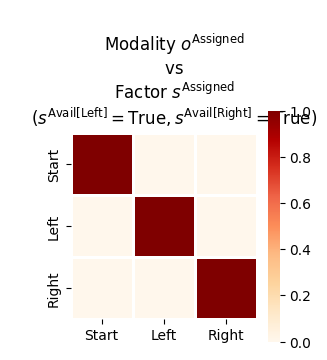

In [150]:
## Condition on sAvail and display the remaining indices (oAssigned and sAssigned) 
plot_likelihood(
    _A[m][
        :,
        :,
        lup['sAvail']['Left'].index(True),
        lup['sAvail']['Right'].index(True)
    ], 
    title_str="""
    Modality $o^{\mathrm{Assigned}}$
    vs
    Factor $s^{\mathrm{Assigned}}$
    ($s^{\mathrm{Avail[Left]}}=\mathrm{True}, s^{\mathrm{Avail[Right]}}=\mathrm{True}$)""",
    ylabels=lup['oAssigned'],
    xlabels=lup['sAssigned'],
    size=(3,3)
)


##### Observation Modality $o^{\mathrm{Rew[Left]}}$


##### A[m] or $P(o^{\mathrm{Rew[Left]}}_{t}\mid \mathbf{s}_t)$

In [151]:
## Modality: oRew[Left]
## write down first combination just to get started:
##       oRew[Left] sAssigned sAvail[Left] sAvail[Right]
## _A[m][0,         0,        0,           0]         = 
## _A[m][1,         0,        0,           0]         = 
## _A[m][2,         0,        0,           0]         = 

## WORKS, BUT ASSIGNS MORE SIMPLISTICALLY & EQUALLY
## m = 1
# for i in range(len(_lup['sAssigned'])):
#     for j in range(len(_lup['sAvail']['Left'])):
#         for k in range(len(_lup['sAvail']['Right'])):
#             ## print(i,j,k)
#             _A[m][0, i, j, k] = 0
#             _A[m][1, i, j, k] = 1/2
#             _A[m][2, i, j, k] = 1/2
m = 1
p_reward = 0.7 ## probability of getting a rewarding outcome from an available arm; matches p_reward_env (section 4.6.1) for a smooth VFE
## FIX: the reward outcome for the Left arm depends on sAvail[Left] (axis 2 of A[m]),
##      Reward when available, Loss when not; if the Left arm is not played -> Null
##                    sAvail[Left]=False  sAvail[Left]=True
rew_given_avail = np.array([ [p_reward,          1.0-p_reward],   ## Loss
                             [1.0-p_reward,      p_reward    ] ]) ## Reward
for i,lab in enumerate(lup['sAssigned']):
    if lab == 'Left':
        _A[m][1:, i, :, :] = rew_given_avail[:, :, None] ## same for every value of the other arm's sAvail
    else: ## 'Start' or the other arm played
        _A[m][0, i, :, :] = 1.0 ## Null

print(m, _A[m].shape)
_A[m] ## 3 cuboids of 3x2x2

1 (3, 3, 2, 2)


array([[[[1. , 1. ],
         [1. , 1. ]],

        [[0. , 0. ],
         [0. , 0. ]],

        [[1. , 1. ],
         [1. , 1. ]]],


       [[[0. , 0. ],
         [0. , 0. ]],

        [[0.7, 0.7],
         [0.3, 0.3]],

        [[0. , 0. ],
         [0. , 0. ]]],


       [[[0. , 0. ],
         [0. , 0. ]],

        [[0.3, 0.3],
         [0.7, 0.7]],

        [[0. , 0. ],
         [0. , 0. ]]]])

In [152]:
is_normalized(_A[m])

True

<Figure size 300x300 with 0 Axes>

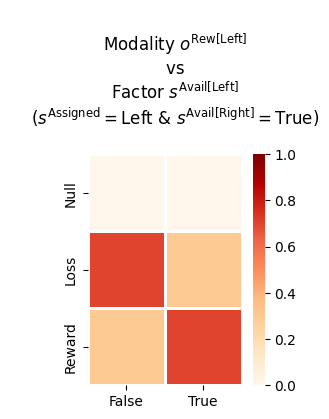

In [153]:
plot_likelihood(
    _A[m][
        :, 
        lup['sAssigned'].index('Left'), 
        :, 
        lup['sAvail']['Right'].index(True)
    ], 
    title_str="""
    Modality $o^{\mathrm{Rew[Left]}}$
    vs
    Factor $s^{\mathrm{Avail[Left]}}$
    ($s^{\mathrm{Assigned}}=\mathrm{Left}\ &\ s^{\mathrm{Avail[Right]}}=\mathrm{True}$)
    """,
    ylabels=lup['oRew']['Left'],
    xlabels=lup['sAvail']['Left'],
    size=(3,3)
)


##### Observation Modality $o^{\mathrm{Rew[Right]}}$

##### A[m] or $P(o^{\mathrm{Rew[Right]}}_{t}\mid \mathbf{s}_t)$

In [154]:
## Modality: oRew[Right]
## write down first combination just to get started:
##       oRew[Right] sAssigned sAvail[Left] sAvail[Right]
## _A[m][0,          0,        0,           0]         = 
## _A[m][1,          0,        0,           0]         = 
## _A[m][2,          0,        0,           0]         = 

m = 2
p_reward = 0.7 ## probability of getting a rewarding outcome from an available arm; matches p_reward_env (section 4.6.1) for a smooth VFE
## FIX: the reward outcome for the Right arm depends on sAvail[Right] (axis 3 of A[m]),
##      Reward when available, Loss when not; if the Right arm is not played -> Null
##                    sAvail[Right]=False  sAvail[Right]=True
rew_given_avail = np.array([ [p_reward,          1.0-p_reward],   ## Loss
                             [1.0-p_reward,      p_reward    ] ]) ## Reward
for i,lab in enumerate(lup['sAssigned']):
    if lab == 'Right':
        _A[m][1:, i, :, :] = rew_given_avail[:, None, :] ## same for every value of the other arm's sAvail
    else: ## 'Start' or the other arm played
        _A[m][0, i, :, :] = 1.0 ## Null

print(m, _A[m].shape)
_A[m] ## 3 cuboids of 3x2x2

2 (3, 3, 2, 2)


array([[[[1. , 1. ],
         [1. , 1. ]],

        [[1. , 1. ],
         [1. , 1. ]],

        [[0. , 0. ],
         [0. , 0. ]]],


       [[[0. , 0. ],
         [0. , 0. ]],

        [[0. , 0. ],
         [0. , 0. ]],

        [[0.7, 0.3],
         [0.7, 0.3]]],


       [[[0. , 0. ],
         [0. , 0. ]],

        [[0. , 0. ],
         [0. , 0. ]],

        [[0.3, 0.7],
         [0.3, 0.7]]]])

In [155]:
is_normalized(_A[m])

True

<Figure size 300x300 with 0 Axes>

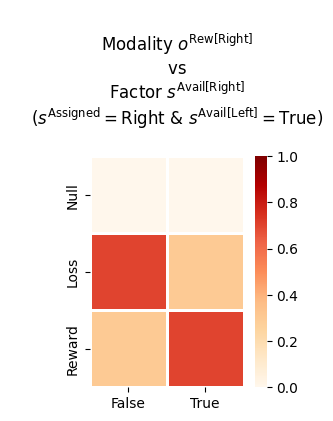

In [156]:
plot_likelihood(
    _A[m][
        :, 
        lup['sAssigned'].index('Right'), 
        lup['sAvail']['Left'].index(True),
        :
    ], 
    title_str="""
    Modality $o^{\mathrm{Rew[Right]}}$
    vs
    Factor $s^{\mathrm{Avail[Right]}}$
    ($s^{\mathrm{Assigned}}=\mathrm{Right}\ &\ s^{\mathrm{Avail[Left]}}=\mathrm{True}$)
    """,
    ylabels=lup['oRew']['Right'],
    xlabels=lup['sAvail']['Right'],
    size=(3,3)
)


##### Observation Modality $o^{\mathrm{Avail[Left]}}$

##### A[m] or $P(o^{\mathrm{Avail[Left]}}_{t}\mid \mathbf{s}_t)$

In [157]:
# _A = np_zeros_list(_A_shapes) # REMOVE !!!!!!!!!!!!

## Modality: oAvail[Left]
## write down first combination just to get started:
##       oAvail[Left] sAssigned sAvail[Left] sAvail[Right]
## _A[m][0,           0,        0,           0]         = 
## _A[m][1,           0,        0,           0]         = 

m = 3
for i in range(len(lup['sAssigned'])):
    # for j in range(len(lup['sAvail']['Left'])):
        for k in range (len(lup['sAvail']['Right'])):
            # _A[m][0, i, j, k] = 0.5
            # _A[m][1, i, j, k] = 0.5
            _A[m][:, i, :, k] = np.eye(len(lup['oAvail']['Left']))
print(m, _A[m].shape)
_A[m] ## 2 cuboids of 3x2x2

3 (2, 3, 2, 2)


array([[[[1., 1.],
         [0., 0.]],

        [[1., 1.],
         [0., 0.]],

        [[1., 1.],
         [0., 0.]]],


       [[[0., 0.],
         [1., 1.]],

        [[0., 0.],
         [1., 1.]],

        [[0., 0.],
         [1., 1.]]]])

In [158]:
is_normalized(_A[m])

True

<Figure size 300x300 with 0 Axes>

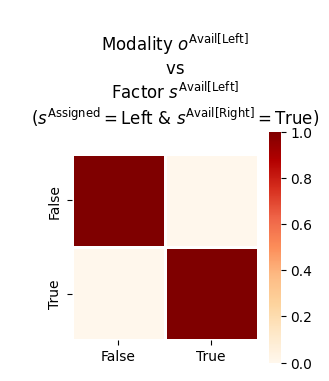

In [159]:
plot_likelihood(
    _A[m][
        :, 
        lup['sAssigned'].index('Left'), 
        :, 
        lup['sAvail']['Right'].index(True)
    ], 
    title_str="""
    Modality $o^{\mathrm{Avail[Left]}}$
    vs
    Factor $s^{\mathrm{Avail[Left]}}$
    ($s^{\mathrm{Assigned}}=\mathrm{Left}\ &\ s^{\mathrm{Avail[Right]}}=\mathrm{True}$)
    """,
    ylabels=lup['oAvail']['Left'],
    xlabels=lup['sAvail']['Left'],
    size=(3,3)
)

##### Observation Modality $o^{\mathrm{Avail[Right]}}$

##### A[m] or $P(o^{\mathrm{Avail[Right]}}_{t}\mid \mathbf{s}_t)$

In [160]:
# _A = np_zeros_list(_A_shapes) # REMOVE !!!!!!!!!!!!

## Modality: oAvail[Left]
## write down first combination just to get started:
##       oAvail[Right] sAssigned sAvail[Left] sAvail[Right]
## _A[m][0,            0,        0,           0]         = 
## _A[m][1,            0,        0,           0]         = 

m = 4
for i in range(len(lup['sAssigned'])):
    for j in range (len(lup['sAvail']['Left'])):
        for k in range(len(lup['sAvail']['Right'])):
            # _A[m][0, i, j, k] = 0.5
            # _A[m][1, i, j, k] = 0.5
            _A[m][:, i, j, :] = np.eye(len(lup['oAvail']['Right']))
print(m, _A[m].shape)
_A[m] ## 2 cuboids of 3x2x2


4 (2, 3, 2, 2)


array([[[[1., 0.],
         [1., 0.]],

        [[1., 0.],
         [1., 0.]],

        [[1., 0.],
         [1., 0.]]],


       [[[0., 1.],
         [0., 1.]],

        [[0., 1.],
         [0., 1.]],

        [[0., 1.],
         [0., 1.]]]])

In [161]:
is_normalized(_A[m])

True

<Figure size 300x300 with 0 Axes>

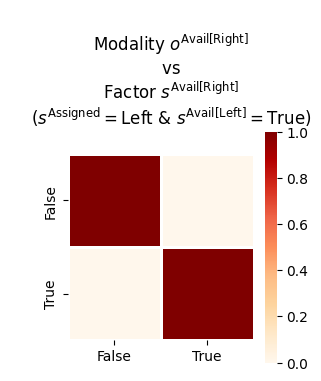

In [162]:
plot_likelihood(
    _A[m][
        :, 
        lup['sAssigned'].index('Left'), 
        lup['sAvail']['Left'].index(True),
        :, 
    ], 
    title_str="""
    Modality $o^{\mathrm{Avail[Right]}}$
    vs
    Factor $s^{\mathrm{Avail[Right]}}$
    ($s^{\mathrm{Assigned}}=\mathrm{Left}\ &\ s^{\mathrm{Avail[Left]}}=\mathrm{True}$)
    """,
    ylabels=lup['oAvail']['Right'],
    xlabels=lup['sAvail']['Right'],
    size=(3,3)
)

In [163]:
is_normalized(_A)

True

In [164]:
print(f'=== _s_dims:\n{_s_dims}')
print(f'=== _o_dims:\n{_o_dims}')
## _A

=== _s_dims:
[3, 2, 2]
=== _o_dims:
[3, 3, 3, 2, 2]


#### 4.5.3.2 Transition likelihood matrix, $\mathbf B$ or $P(s_{t}\mid s_{t-1}, u_{t-1})$

In [165]:
print(_a_dims)
print(_s_dims)

[3, 1, 1]
[3, 2, 2]


In [166]:
_B_shapes = [[s_dim, s_dim, _a_dims[f]] for f,s_dim in enumerate(_s_dims)]
_B_shapes

[[3, 3, 3], [2, 2, 1], [2, 2, 1]]

In [167]:
_B = np_zeros_list(_B_shapes)
_B
## 3 matrices of 3x3
## 2 matrices of 2x1
## 2 matrices of 2x1

[array([[[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],
 
        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]],
 
        [[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]]]),
 array([[[0.],
         [0.]],
 
        [[0.],
         [0.]]]),
 array([[[0.],
         [0.]],
 
        [[0.],
         [0.]]])]

##### State Factor $s^{\mathrm{Assigned}}$

##### B[f] or $P(s^{\mathrm{Assigned}}_t\mid s^{\mathrm{Assigned}}_{t-1}, a^{\mathrm{Assign}}_{t-1})$

In [168]:
f = 0
for i in range(len(lup['sAssigned'])):
  _B[f][i, :, i] = 1.0
_B[f]
## 4 matrices of 4x4

array([[[1., 0., 0.],
        [1., 0., 0.],
        [1., 0., 0.]],

       [[0., 1., 0.],
        [0., 1., 0.],
        [0., 1., 0.]],

       [[0., 0., 1.],
        [0., 0., 1.],
        [0., 0., 1.]]])

In [169]:
is_normalized(_B[f])

True

<Figure size 300x300 with 0 Axes>

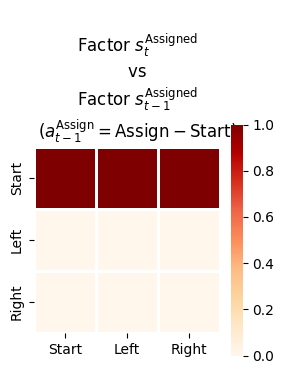

In [170]:
plot_likelihood(
    _B[f][:,:,lup['aAssign'].index('Assign-Start')],
    title_str="""
    Factor $s^{\mathrm{Assigned}}_{t}$
    vs
    Factor $s^{\mathrm{Assigned}}_{t-1}$
    ($a^{\mathrm{Assign}}_{t-1}=\mathrm{Assign-Start}$)""",
    ylabels=lup['sAssigned'],
    xlabels=lup['sAssigned'],
    size=(3,3)
)

<Figure size 300x300 with 0 Axes>

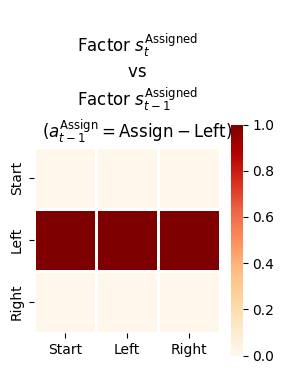

In [171]:
plot_likelihood(
    _B[f][:,:,lup['aAssign'].index('Assign-Left')],
    title_str="""
    Factor $s^{\mathrm{Assigned}}_{t}$
    vs
    Factor $s^{\mathrm{Assigned}}_{t-1}$
    ($a^{\mathrm{Assign}}_{t-1}=\mathrm{Assign-Left}$)""",
    ylabels=lup['sAssigned'],
    xlabels=lup['sAssigned'],
    size=(3,3)
)

<Figure size 300x300 with 0 Axes>

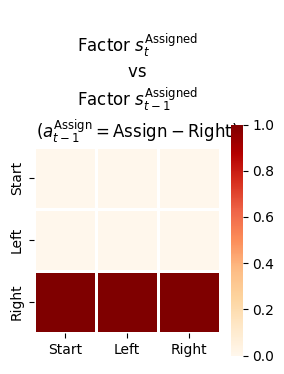

In [172]:
plot_likelihood(
    _B[f][:,:,lup['aAssign'].index('Assign-Right')],
    title_str="""
    Factor $s^{\mathrm{Assigned}}_{t}$
    vs
    Factor $s^{\mathrm{Assigned}}_{t-1}$
    ($a^{\mathrm{Assign}}_{t-1}=\mathrm{Assign-Right}$)""",
    ylabels=lup['sAssigned'],
    xlabels=lup['sAssigned'],
    size=(3,3)
)

##### State factor $s^{\mathrm{Avail[Left]}}$

##### B[f] or $P(s^{\mathrm{Avail[Left]}}_t\mid s^{\mathrm{Avail[Left]}}_{t-1}, a^{\mathrm{Null1}}_{t-1})$

In [173]:
f = 1
_B[f][
    :,
    :,
    0 ## for uncontrollable, 0 for the only value: 'null/no-action'
] = np.eye(len(lup['sAvail']['Left']))
_B[f]

array([[[1.],
        [0.]],

       [[0.],
        [1.]]])

In [174]:
is_normalized(_B[f])

True

<Figure size 300x300 with 0 Axes>

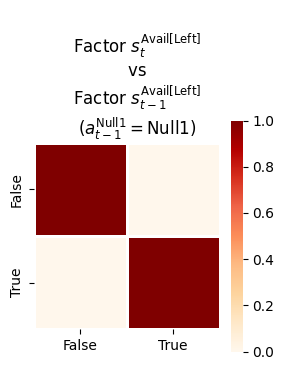

In [175]:
plot_likelihood(
    _B[f][:,:,lup['aNull1'].index('Null1')],
    title_str="""
    Factor $s^{\mathrm{Avail[Left]}}_{t}$
    vs
    Factor $s^{\mathrm{Avail[Left]}}_{t-1}$
    ($a^{\mathrm{Null1}}_{t-1}=\mathrm{Null1}$)""",
    ylabels=lup['sAvail']['Left'],
    xlabels=lup['sAvail']['Left'],
    size=(3,3)
)

##### State factor $s^{\mathrm{Avail[Right]}}$

##### B[f] or $P(s^{\mathrm{Avail[Right]}}_t\mid s^{\mathrm{Avail[Right]}}_{t-1}, a^{\mathrm{Null2}}_{t-1})$

In [176]:
f = 2
_B[f][
    :,
    :,
    0 ## for uncontrollable, 0 for the only value: 'null/no-action'
] = np.eye(len(lup['sAvail']['Right']))
_B[f]

array([[[1.],
        [0.]],

       [[0.],
        [1.]]])

In [177]:
is_normalized(_B[f])

True

<Figure size 300x300 with 0 Axes>

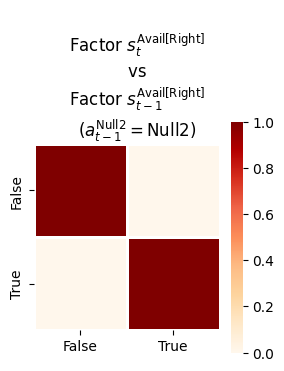

In [178]:
plot_likelihood(
    _B[f][:,:,lup['aNull2'].index('Null2')],
    title_str="""
    Factor $s^{\mathrm{Avail[Right]}}_{t}$
    vs
    Factor $s^{\mathrm{Avail[Right]}}_{t-1}$
    ($a^{\mathrm{Null2}}_{t-1}=\mathrm{Null2}$)""",
    ylabels=lup['sAvail']['Right'],
    xlabels=lup['sAvail']['Right'],
    size=(3,3)
)

In [179]:
print(f'=== _a_dims:\n{_a_dims}')
print(f'=== _s_dims:\n{_s_dims}')
_B

=== _a_dims:
[3, 1, 1]
=== _s_dims:
[3, 2, 2]


[array([[[1., 0., 0.],
         [1., 0., 0.],
         [1., 0., 0.]],
 
        [[0., 1., 0.],
         [0., 1., 0.],
         [0., 1., 0.]],
 
        [[0., 0., 1.],
         [0., 0., 1.],
         [0., 0., 1.]]]),
 array([[[1.],
         [0.]],
 
        [[0.],
         [1.]]]),
 array([[[1.],
         [0.]],
 
        [[0.],
         [1.]]])]

In [180]:
is_normalized(_B)

True

#### 4.5.3.3 Prior preferences, $\mathbf C$ (the C vectors)

In [181]:
print(_o_dims)

[3, 3, 3, 2, 2]


In [182]:
## For C, each observation modality has a VECTOR, NOT a MATRIX/TENSOR as in the case of A
_C = np_zeros_list(_o_dims) ##.
_C

[array([0., 0., 0.]),
 array([0., 0., 0.]),
 array([0., 0., 0.]),
 array([0., 0.]),
 array([0., 0.])]

In [183]:
## "oAssigned"
## leave _C[0]

## "oRew[Left]"
_C[1][1] = -4.0 ##. do not want to see the oRew[Left] == 'Loss' observation
# _C[1][1] = -8.0 ##. do not want to see the oRew[Left] == 'Loss' observation
_C[1][2] = 4.0 ##. want to see the oRew[Left] == 'Reward' observation 
# _C[1][2] = 8.0 ##. want to see the oRew[Left] == 'Reward' observation 

## "oRew[Right]"
_C[2][1] = -4.0 ##. do not want to see the oRew[Right] == 'Loss' observation
_C[2][2] = 4.0 ##. want to see the oRew[Right] == 'Reward' observation 

## "oAvail[Left]"
## leave _C[3]

## "oAvail[Right]"
## leave _C[4]

_C

[array([0., 0., 0.]),
 array([ 0., -4.,  4.]),
 array([ 0., -4.,  4.]),
 array([0., 0.]),
 array([0., 0.])]

In [184]:
softmax(jnp.asarray(_C[1]))


Array([1.7980287e-02, 3.2932044e-04, 9.8169035e-01], dtype=float32)

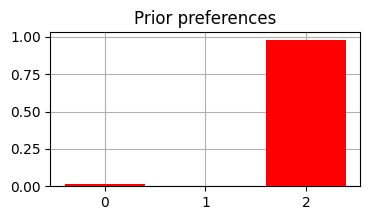

In [185]:
plot_beliefs(softmax(jnp.asarray(_C[1])), title_str="Prior preferences", size=(4,2))


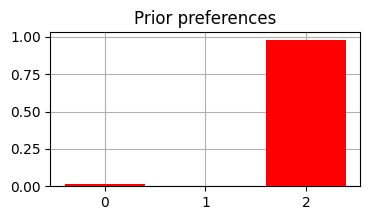

In [186]:
plot_beliefs(softmax(jnp.asarray(_C[2])), title_str="Prior preferences", size=(4,2))


#### 4.5.3.4 Prior over (initial) hidden states, $\mathbf D$ (the D vectors)

In [187]:
print(_s_dims)

[3, 2, 2]


In [188]:
## For D, each state factor has a VECTOR, NOT a MATRIX/TENSOR as in the case of B
_D = np_zeros_list(_s_dims)
_D

[array([0., 0., 0.]), array([0., 0.]), array([0., 0.])]

In [189]:
## "sAssigned"
## _D[0] = [0.5, 0.5] ## breaks later, has to be np.array()
## _D[0] = np.array([1.0, 0.0, 0.0, 0.0]) ##. certain about 'Start'
_D[0] = np.array([1.0, 0.0, 0.0]) ##. certain about 'Start'
_D

[array([1., 0., 0.]), array([0., 0.]), array([0., 0.])]

In [190]:
## "sAvail[Left]"
## _D[1] = [1.0, 0.0, 0.0, 0.0] ## breaks later, has to be np.array()
# _D[1] = np.array([0.5, 0.5])
_D[1] = np.array([1.0, 0.0])
_D

[array([1., 0., 0.]), array([1., 0.]), array([0., 0.])]

In [191]:
## "sAvail[Right]"
# _D[2] = np.array([0.5, 0.5])
_D[2] = np.array([0.0, 1.0])
_D

[array([1., 0., 0.]), array([1., 0.]), array([0., 1.])]

In [192]:
print(f'Beliefs about starting location: {_D[0]}')
print(f'Beliefs about which arms are available to provide reward: {_D[1]}, {_D[2]}')

Beliefs about starting location: [1. 0. 0.]
Beliefs about which arms are available to provide reward: [1. 0.], [0. 1.]


## 4.6 Active Inference / Agent Evaluation

Now we'll write a function that will take the agent, the environment, and a time length and run the active inference loop

In [193]:
def get_policy_labels(policies):
    H = len(policies[0]) ## use first policy to find policy_len or time horizon H
    labels = []
    for p in range(len(policies)): ## for each action-sequence / policy
        lab = ''
        for a in range(H): ## for each action
            if a < H - 1:
                ## lab = lab+f"{[lup['aAssign'][policies[p][a][0]],_lup['aNull1'][policies[p][a][1]],_lup['aNull2'][policies[p][a][2]]]} ---> "
                lab = lab+f"{[lup['aAssign'][policies[p][a][0]], '', '']} ---> "
            else:
                ## lab = lab+f"{[lup['aAssign'][policies[p][a][0]],_lup['aNull1'][policies[p][a][1]],_lup['aNull2'][policies[p][a][2]]]}"
                lab = lab+f"{[lup['aAssign'][policies[p][a][0]], '', '']}"
        labels.append(lab)
    return labels

## for nested entries in lup (in addition to normal entries)
def get_val_names(names): ## fac/mod names
    val_names = []
    for omn in names:
        if omn.find('[') == -1: ## no '[' in name
            val_names.append(lup[omn])
        else:
            hi = omn.split('[')[0]
            lo = omn.split('[')[1][:-1]
            val_names.append(lup[hi][lo])
    return val_names

a_fac_names = ['aAssign', 'aNull1', 'aNull2'] ## control factor names
s_fac_names = [ ## state factor names
  'sAssigned', 
  'sAvail[Left]', 'sAvail[Right]'
]
sˣ_fac_names = [ ## state factor names
  'sˣAssigned', 
  'sˣAvail[Left]', 'sˣAvail[Right]'
]
o_mod_names = [ ## observation modality names
  'oAssigned', 
  'oRew[Left]', 'oRew[Right]',
  'oAvail[Left]', 'oAvail[Right]'
]

a_val_names = get_val_names(a_fac_names); print(f'{a_val_names=}')
s_val_names = get_val_names(s_fac_names); print(f'{s_val_names=}')
sˣ_val_names = get_val_names(sˣ_fac_names); print(f'{sˣ_val_names=}')
o_val_names = get_val_names(o_mod_names); print(f'{o_val_names=}')

def run_active_inference_loop(agt, env, T=5, rng_key=None):
  if rng_key is None:
    rng_key = jr.PRNGKey(0)
  obs_lab = env.reset() ## reset the environment and get an initial observation
  obs_idx = [
    lup['oAssigned'].index(obs_lab[0]),
    lup['oRew']['Left'].index(obs_lab[1]),
    lup['oRew']['Right'].index(obs_lab[2]),
    lup['oAvail']['Left'].index(obs_lab[3]),
    lup['oAvail']['Right'].index(obs_lab[4]),
  ]
  print(f'Number of policies: {math.prod(_a_dims)**agt.policy_len=}')
  print(f'\tbecause {_a_dims=}, {agt.policy_len=}')
  policies = np.asarray(agt.policies.policy_arr) ## (num_policies, policy_len, num_factors)
  policy_labels = get_policy_labels(policies)

  ## JAX: the agent no longer stores beliefs internally; we carry the empirical prior ourselves
  prior = agt.D ## at t=0 the prior over states is D

  for t in range(T):                               ##. with a slide
    print(f"\n===================== Time {t}: =====================")
    
    #### infer states
    obs = [jnp.array([o]) for o in obs_idx] ## leading batch dim (batch_size=1)
    qs, info = agt.infer_states(obs, empirical_prior=prior, return_info=True) ##. infer.
    QIsI = [np.asarray(q[0, -1]) for q in qs] ## drop batch & time dims -> one vector per factor

    ## VFE
    VFE = float(info['vfe'][0])
    print(f'{VFE=}')
    VFEː.append(VFE)

    ## QIsI
    plot_beliefs(QIsI[0], title_str=r"$Q(s^{\mathrm{Assigned}}_{t})$"+f" at t = {t}", xlabels=lup['sAssigned'])
    plot_beliefs(QIsI[1], title_str=r"$Q(s^{\mathrm{Avail[Left]}}_{t})$"+f" at t = {t}", xlabels=lup['sAvail']['Left'])
    plot_beliefs(QIsI[2], title_str=r"$Q(s^{\mathrm{Avail[Right]}}_{t})$"+f" at t = {t}", xlabels=lup['sAvail']['Right'])
    
    sˣ_facs['sˣAssigned'].append(env.sˣAssigned)
    sˣ_facs['sˣAvail']['Left'].append(env.sˣAvail['Left'][t])
    sˣ_facs['sˣAvail']['Right'].append(env.sˣAvail['Right'][t])

    for sfi, sfn in enumerate(s_fac_names):
        if sfn.find('[') == -1: ## no '[' in name
            s_facs[sfn].append( lup[sfn][int(np.argmax(QIsI[sfi].round(3)))] )
        else:
            hi = sfn.split('[')[0]
            lo = sfn.split('[')[1][:-1]
            s_facs[hi][lo].append( lup[hi][lo][int(np.argmax(QIsI[sfi].round(3)))] )
    print('s_facs:'); print(s_facs)
    print('sˣ_facs:'); print(sˣ_facs)

    #### infer policies
    print(f'\t%%% Policies %%%')
    q_pi, neg_efe = agt.infer_policies(qs)
    QIpiI = np.asarray(q_pi[0])
    EFE = -np.asarray(neg_efe[0]) ## JAX returns the NEGATIVE expected free energy
    ## efe
    print(f'{len(EFE)=}'); ##print(f'EFE: {np.round(EFE, 2)}')
    print(f'{np.argmin(EFE)=}'); print(f'{np.min(EFE)=}')
    lowest_EFE_idx = int(np.argmin(EFE))
    print(f'LOWEST EFE in {lowest_EFE_idx}: {EFE[lowest_EFE_idx]}')
    ## plot_FE(
    #   EFE, 
    #   title_str=r"$G$"+f" at t = {t}", 
    #   size=(12,1)
    # )
    EFEː.append(EFE)
    ## qIpiI
    print(f'{len(QIpiI)=}'); print(f'QIpiI: {np.round(QIpiI, 2)}')
    print(f'{np.argmax(QIpiI)=}'); print(f'{np.max(QIpiI)=}')
    print(f'BEST QIpiI: {np.round(QIpiI[lowest_EFE_idx], 2)}')
    plot_beliefs(
      QIpiI, 
      title_str=r"$Q(\pi_{t})$"+f" at t = {t}", 
      xlabels=policy_labels,
      size=(12,2),
      label_rotation=-90 ## policy labels read top-to-bottom (tilt head to the right)
    )
    QIpiIː.append(QIpiI)
    
    print(f'### ACT FUTURE ###')
    rng_key, key_action = jr.split(rng_key)
    action = agt.sample_action(q_pi, rng_key=jr.split(key_action, agt.batch_size)) ## shape (batch, num_factors)
    act_idx = np.asarray(action[0]); print(f'!!!!!!!!!! {act_idx=}') ##. Act future &
    act_idx_controllable = int(act_idx[0]) ## aAssign; only ele 0 used, rest of state factors uncontrollable
    act_lab_controllable = lup['aAssign'][act_idx_controllable] ##.
    for afi, afn in enumerate(a_fac_names):
        a_facs[afn].append(a_val_names[afi][int(act_idx[afi])])
    print('a_facs:'); print(a_facs)

    ## JAX: propagate beliefs through B under the chosen action -> prior for the next step
    prior = agt.update_empirical_prior(action, qs)

    print(f'### NEXT OBSERVE ###')
    obs_lab = env.step(t, act_lab_controllable)    ##. next observe, howto
    obs_idx = [
      lup['oAssigned'].index(obs_lab[0]),
      lup['oRew']['Left'].index(obs_lab[1]),
      lup['oRew']['Right'].index(obs_lab[2]),
      lup['oAvail']['Left'].index(obs_lab[3]),
      lup['oAvail']['Right'].index(obs_lab[4]),
    ]
    for omi, omn in enumerate(o_mod_names):
        if omn.find('[') == -1: ## no '[' in name
            o_mods[omn].append( o_val_names[omi][obs_idx[omi]] )
        else:
            hi = omn.split('[')[0]
            lo = omn.split('[')[1][:-1]
            o_mods[hi][lo].append( o_val_names[omi][obs_idx[omi]] )
    print('o_mods:'); print(o_mods)            

    print(f'Action at time {t}: {act_lab_controllable}')
    print(f"sˣAvail[Left] at time {t}: {env.sˣAvail['Left'][t]}")
    print(f'oRew[Left] at time {t}: {obs_lab[1]}')
    print(f'oRew[Right] at time {t}: {obs_lab[2]}')
    print(f'oAvail[Left] at time {t}: {obs_lab[3]}')
    print(f'oAvail[Right] at time {t}: {obs_lab[4]}')    


a_val_names=[['Assign-Start', 'Assign-Left', 'Assign-Right'], ['Null1'], ['Null2']]
s_val_names=[['Start', 'Left', 'Right'], [False, True], [False, True]]
sˣ_val_names=[['Start', 'Left', 'Right'], [False, True], [False, True]]
o_val_names=[['Start', 'Left', 'Right'], ['Null', 'Loss', 'Reward'], ['Null', 'Loss', 'Reward'], [False, True], [False, True]]


### 4.6.1 First evaluation

Now all we have to do is define the bandit environment, choose the length of the simulation, and run the function we wrote above.

Try playing with the hint accuracy and/or reward statistics of the environment - remember this is _different_ than the agent's representation of the reward statistics (i.e. the agent's generative model, e.g. the A or B matrices).

In [194]:
random.seed(20)
env_rng = np.random.default_rng(20) ## seeds the environment's sampling
rng_key = jr.PRNGKey(20) ## seeds the agent (JAX needs explicit keys)


In [195]:
## Create an envir

## this is the "true" reward probability - i.e. how often does the better arm actually 
##   return a reward, as opposed to a loss. REMEMBER: THIS IS INDEPENDENT OF HOW YOU 
##   PARAMETERIZE THE A MATRIX FOR THE REWARD MODALITY
p_reward_env = 0.7
# p_reward_env = 1.0
avails = {
    'Left': [
        False, False, False, False, False, 
        False, False, False, False, False, 
        False, False, False, False, False,
        False, False, False, False, False, 
        False, False, False, False, False, 
        # True,  True,  True,  True,  True,
        # True,  True,  True,  True,  True,
        # True,  True,  True,  True,  True,
        # True,  True,  True,  True,  True,
        # True,  True,  True,  True,  True,
        False, False, False, False, False, 
        False, False, False, False, False, 
        False, False, False, False, False,
        False, False, False, False, False, 
        False, False, False, False, False, 
    ],
    'Right': [
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,
        # False, False, False, False, False, 
        # True,  True,  True,  True,  True,
        # False, False, False, False, False, 
        # True,  True,  True,  True,  True,
        # False, False, False, False, False, 
        # True,  True,  True,  True,  True,
        # False, False, False, False, False, 
        # True,  True,  True,  True,  True,
        # False, False, False, False, False, 
        # True,  True,  True,  True,  True
    ],
}
print(f"{len(avails['Left'])=}")

my_envir = EpistemicMABEnvir(
    avails = avails,
    p_reward=p_reward_env)

pprint(f'my_envir.sˣAvail: {my_envir.sˣAvail}')

len(avails['Left'])=50
("my_envir.sˣAvail: {'Left': [False, False, False, False, False, False, False, "
 'False, False, False, False, False, False, False, False, False, False, False, '
 'False, False, False, False, False, False, False, False, False, False, False, '
 'False, False, False, False, False, False, False, False, False, False, False, '
 'False, False, False, False, False, False, False, False, False, False], '
 "'Right': [True, True, True, True, True, True, True, True, True, True, True, "
 'True, True, True, True, True, True, True, True, True, True, True, True, '
 'True, True, True, True, True, True, True, True, True, True, True, True, '
 'True, True, True, True, True, True, True, True, True, True, True, True, '
 'True, True, True]}')


In [196]:
## Create an agent
## list of the indices of the hidden state factors that are controllable
## sContext_0: uncontrollable; sChoice_1: controllable
controllable_indices = [0] ## aAssign

my_agent = Agent(
    A=[jnp.asarray(a) for a in _A], ## JAX: convert numpy model to jnp arrays
    B=[jnp.asarray(b) for b in _B], 
    C=[jnp.asarray(c) for c in _C], 
    D=[jnp.asarray(d) for d in _D],
    ## number of action values (aChoice_1); aNull_0 has a single value, so 1*4=4
    # policy_len=1, ##. 4**1 = 4 ele
    policy_len=2, ##. 4**2 = 16 ele
    # policy_len=3, ##. 4**3 = 64 ele 
    # policy_len=4, ##. 4**4 = 256 ele 
    control_fac_idx=controllable_indices,
    action_selection="deterministic", ## same as legacy default
    sampling_mode="marginal", ## legacy default; JAX default is "full"
)
my_agent

Agent(
  A=[
    f32[1,3,3,2,2],
    f32[1,3,3,2,2],
    f32[1,3,3,2,2],
    f32[1,2,3,2,2],
    f32[1,2,3,2,2]
  ],
  B=[f32[1,3,3,3], f32[1,2,2,1], f32[1,2,2,1]],
  C=[f32[1,3], f32[1,3], f32[1,3], f32[1,2], f32[1,2]],
  D=[f32[1,3], f32[1,2], f32[1,2]],
  E=f32[1,9],
  pA=None,
  pB=None,
  gamma=weak_f32[1],
  alpha=weak_f32[1],
  policies=Policies(
    _policy_tup=(
      ((0, 0, 0), (0, 0, 0)),
      ((0, 0, 0), (1, 0, 0)),
      ((0, 0, 0), (2, 0, 0)),
      ((1, 0, 0), (0, 0, 0)),
      ((1, 0, 0), (1, 0, 0)),
      ((1, 0, 0), (2, 0, 0)),
      ((2, 0, 0), (0, 0, 0)),
      ((2, 0, 0), (1, 0, 0)),
      ((2, 0, 0), (2, 0, 0))
    ),
    _dtype=dtype('int32'),
    horizon=2,
    num_policies=9
  ),
  inductive_threshold=weak_f32[1],
  inductive_epsilon=weak_f32[1],
  H=None,
  I=[f32[1,1,3], f32[1,1,2], f32[1,1,2]],
  A_dependencies=[[0, 1, 2], [0, 1, 2], [0, 1, 2], [0, 1, 2], [0, 1, 2]],
  B_dependencies=[[0], [1], [2]],
  B_action_dependencies=[[0], [1], [2]],
  action_maps=N

Re-initialized to:
self.sˣAvail={'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}
self.p_reward=0.7
self.sˣAssigned='Start', oRew={'Left': 'Null', 'Right': 'Null'}
Number of policies: math.prod(_a_dims)**agt.policy_len=9
	because _a_dims=[3, 1, 1], agt.policy_len=2

===================== Time 0: =====================
VFE=3.554191241067157e-30


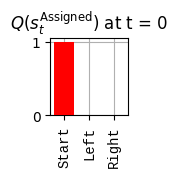

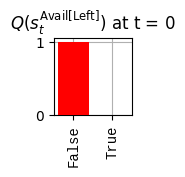

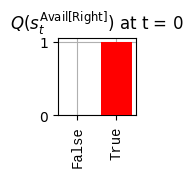

s_facs:
{'sAssigned': ['Start'], 'sAvail': {'Left': [False], 'Right': [True]}}
sˣ_facs:
{'sˣAssigned': ['Start'], 'sˣAvail': {'Left': [False], 'Right': [True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


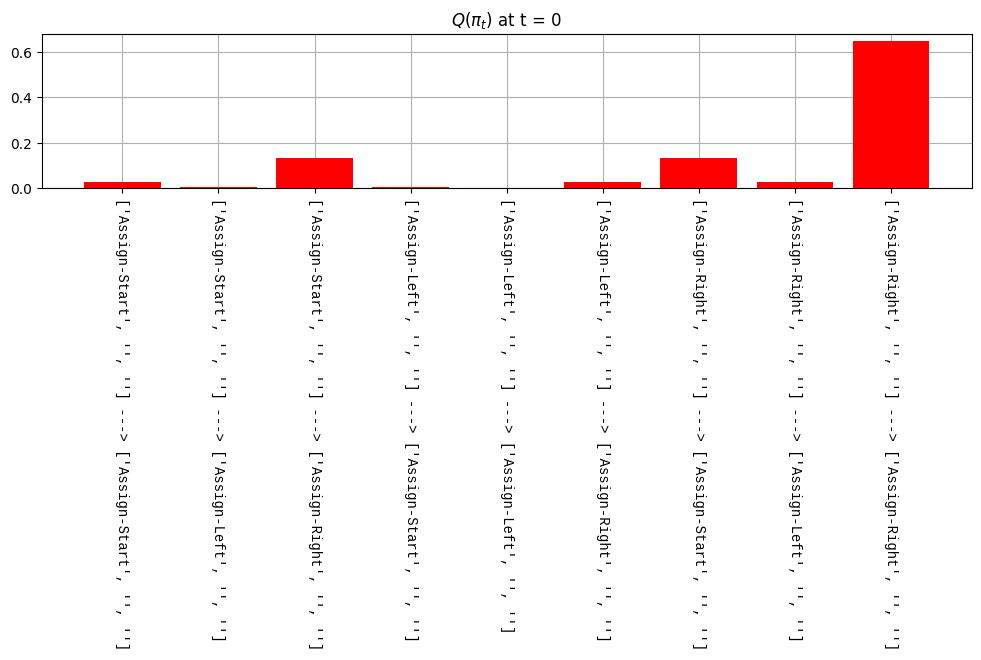

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right'], 'aNull1': ['Null1'], 'aNull2': ['Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right'], 'oRew': {'Left': ['Null'], 'Right': ['Loss']}, 'oAvail': {'Left': [False], 'Right': [True]}}
Action at time 0: Assign-Right
sˣAvail[Left] at time 0: False
oRew[Left] at time 0: Null
oRew[Right] at time 0: Loss
oAvail[Left] at time 0: False
oAvail[Right] at time 0: True

===================== Time 1: =====================
VFE=1.2039728164672852


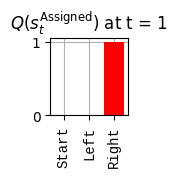

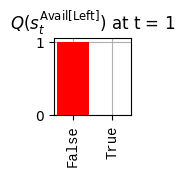

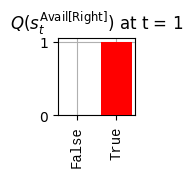

s_facs:
{'sAssigned': ['Start', 'Right'], 'sAvail': {'Left': [False, False], 'Right': [True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right'], 'sˣAvail': {'Left': [False, False], 'Right': [True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


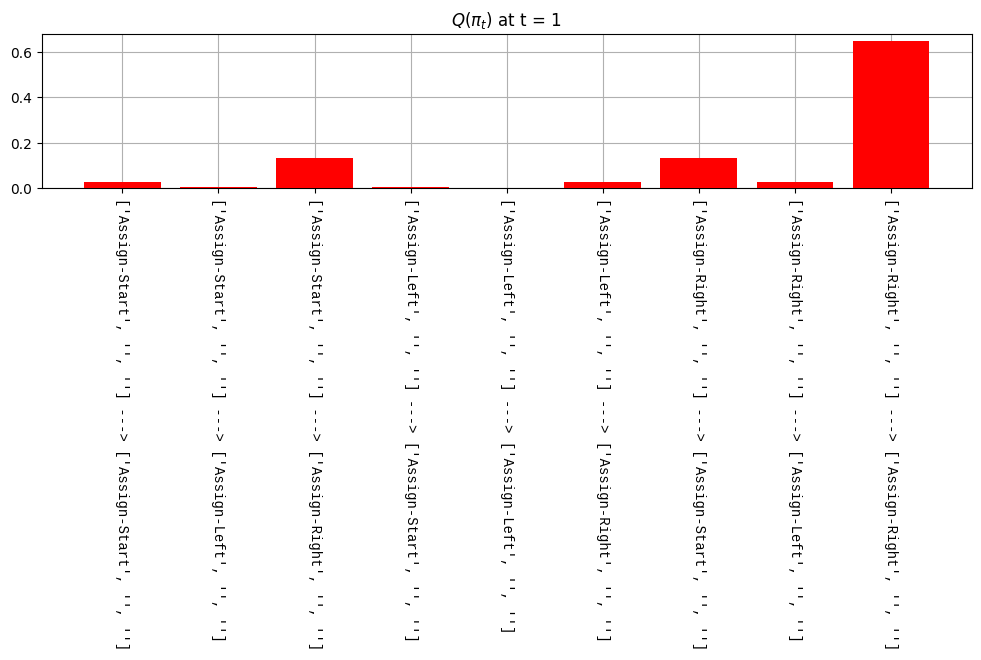

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1'], 'aNull2': ['Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right'], 'oRew': {'Left': ['Null', 'Null'], 'Right': ['Loss', 'Reward']}, 'oAvail': {'Left': [False, False], 'Right': [True, True]}}
Action at time 1: Assign-Right
sˣAvail[Left] at time 1: False
oRew[Left] at time 1: Null
oRew[Right] at time 1: Reward
oAvail[Left] at time 1: False
oAvail[Right] at time 1: True

===================== Time 2: =====================
VFE=0.3566749691963196


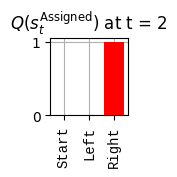

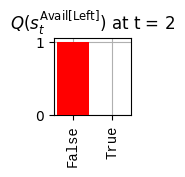

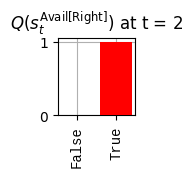

s_facs:
{'sAssigned': ['Start', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False], 'Right': [True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False], 'Right': [True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


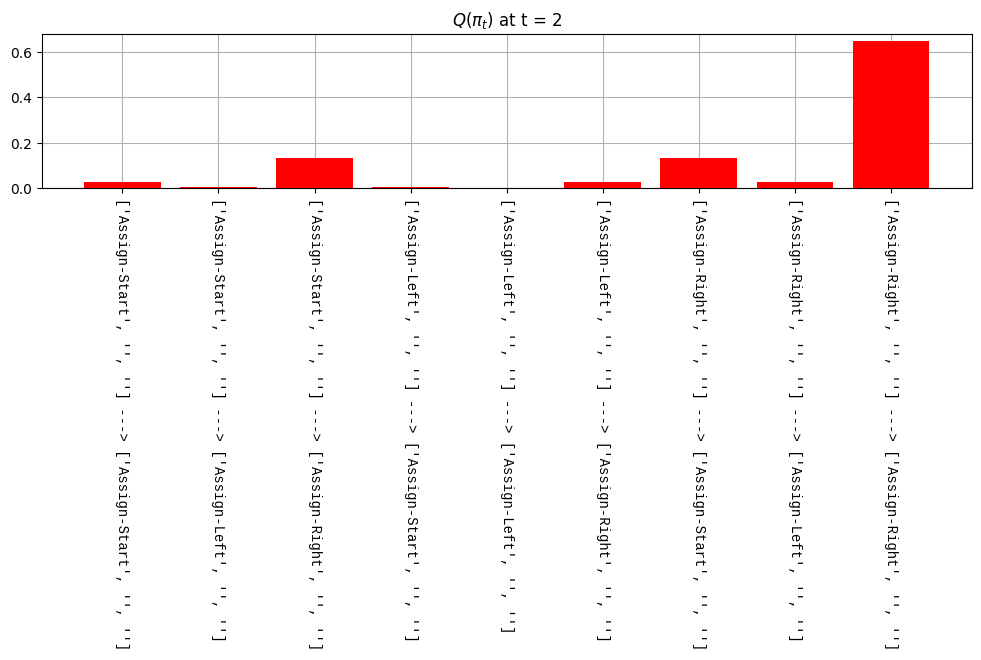

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss']}, 'oAvail': {'Left': [False, False, False], 'Right': [True, True, True]}}
Action at time 2: Assign-Right
sˣAvail[Left] at time 2: False
oRew[Left] at time 2: Null
oRew[Right] at time 2: Loss
oAvail[Left] at time 2: False
oAvail[Right] at time 2: True

===================== Time 3: =====================
VFE=1.2039728164672852


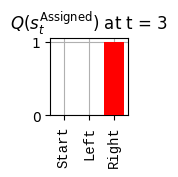

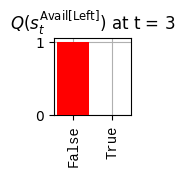

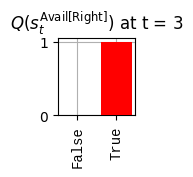

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False], 'Right': [True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False], 'Right': [True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


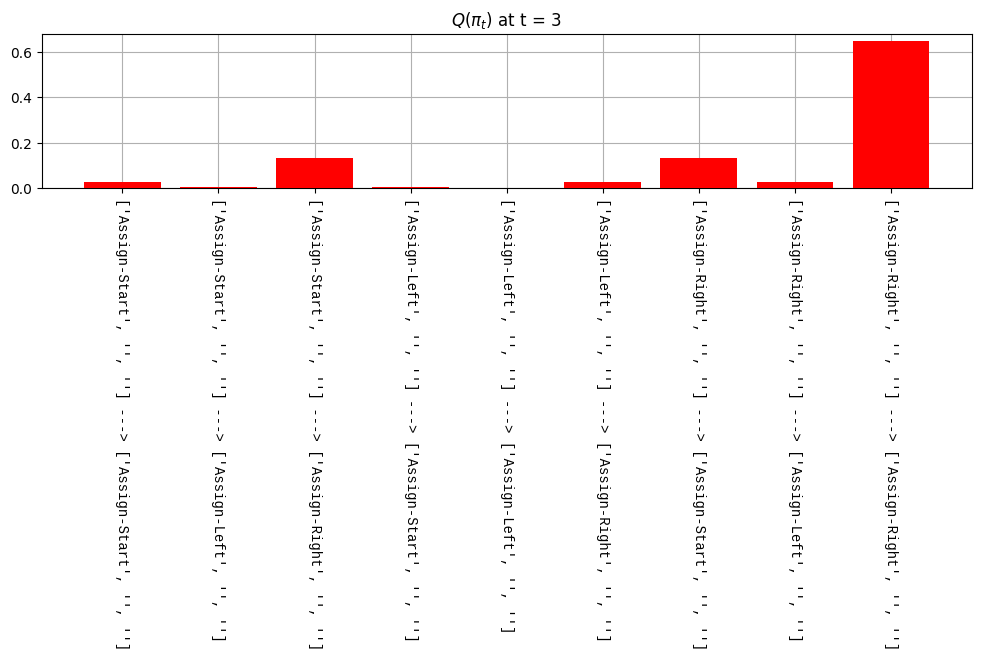

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward']}, 'oAvail': {'Left': [False, False, False, False], 'Right': [True, True, True, True]}}
Action at time 3: Assign-Right
sˣAvail[Left] at time 3: False
oRew[Left] at time 3: Null
oRew[Right] at time 3: Reward
oAvail[Left] at time 3: False
oAvail[Right] at time 3: True

===================== Time 4: =====================
VFE=0.3566749691963196


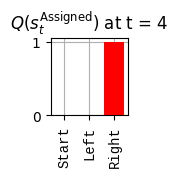

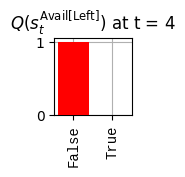

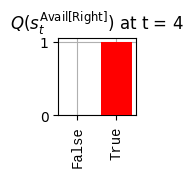

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False], 'Right': [True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False], 'Right': [True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


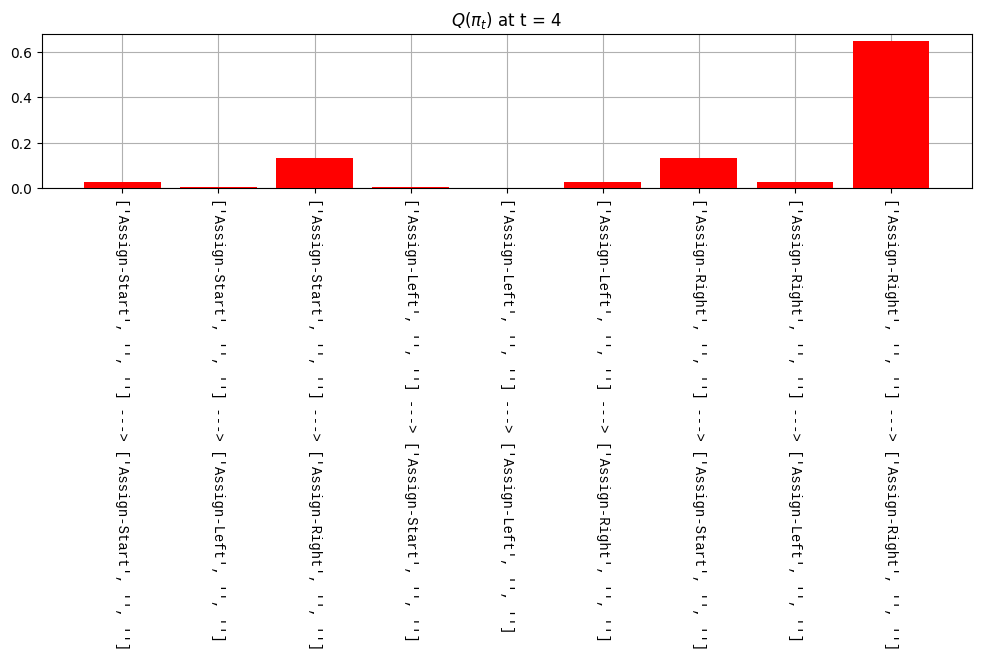

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward']}, 'oAvail': {'Left': [False, False, False, False, False], 'Right': [True, True, True, True, True]}}
Action at time 4: Assign-Right
sˣAvail[Left] at time 4: False
oRew[Left] at time 4: Null
oRew[Right] at time 4: Reward
oAvail[Left] at time 4: False
oAvail[Right] at time 4: True

===================== Time 5: =====================
VFE=0.3566749691963196


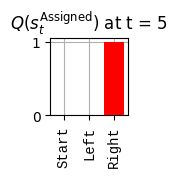

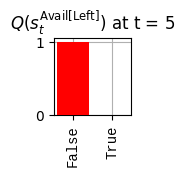

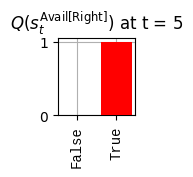

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False], 'Right': [True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False], 'Right': [True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


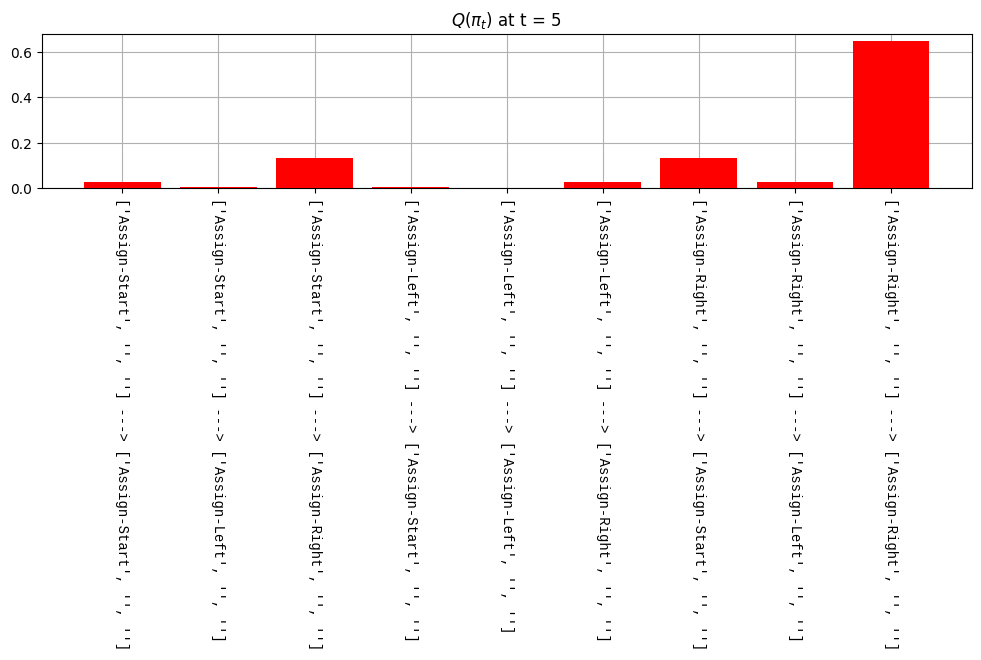

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss']}, 'oAvail': {'Left': [False, False, False, False, False, False], 'Right': [True, True, True, True, True, True]}}
Action at time 5: Assign-Right
sˣAvail[Left] at time 5: False
oRew[Left] at time 5: Null
oRew[Right] at time 5: Loss
oAvail[Left] at time 5: False
oAvail[Right] at time 5: True

===================== Time 6: =====================
VFE=1.2039728164672852


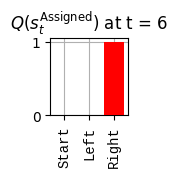

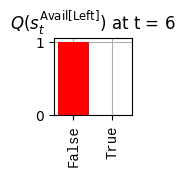

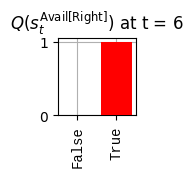

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


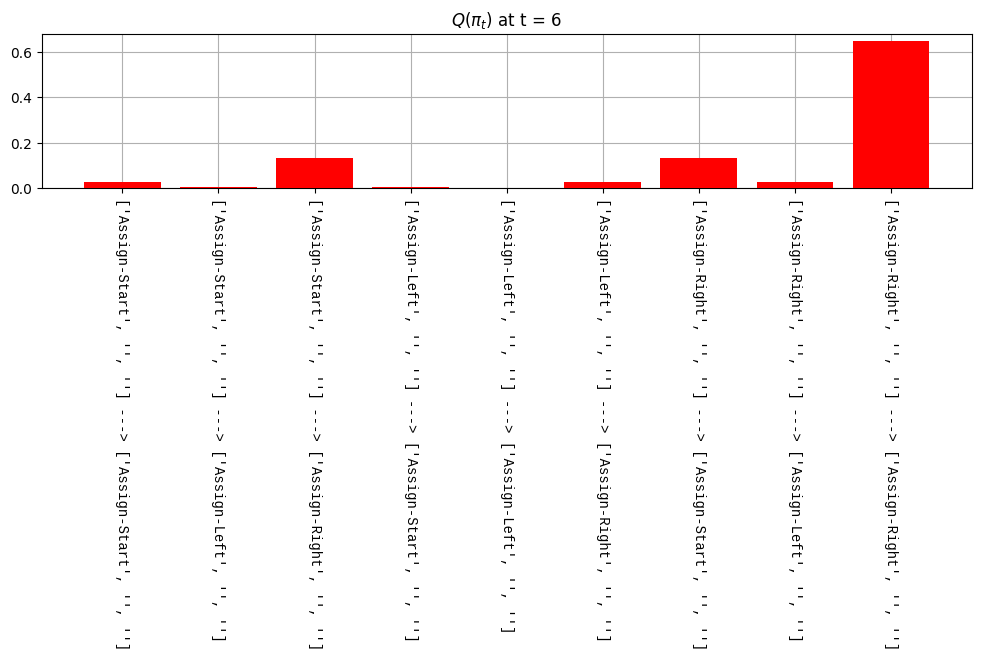

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss', 'Loss']}, 'oAvail': {'Left': [False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True]}}
Action at time 6: Assign-Right
sˣAvail[Left] at time 6: False
oRew[Left] at time 6: Null
oRew[Right] at time 6: Loss
oAvail[Left] at time 6: False
oAvail[Right] at time 6: True

===================== Time 7: =====================
VFE=1.203972

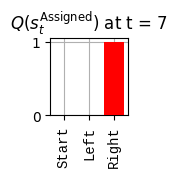

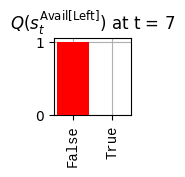

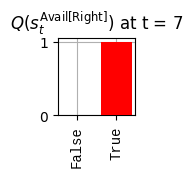

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


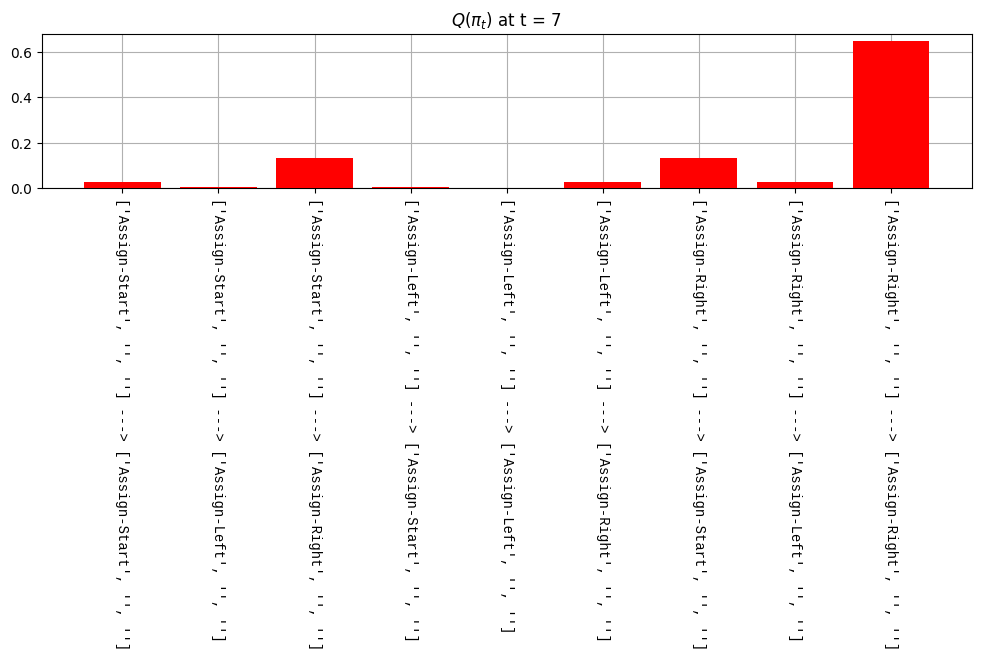

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss', 'Loss', 'Reward']}, 'oAvail': {'Left': [False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True]}}
Action at time 7: Assign-Right
sˣAvail[Left] at time 7: False
oRew[Left] at time 7: Null
oRew[Right] at time 7: Reward
oAvail[Left] at time 7: False
oAvail[Right] at ti

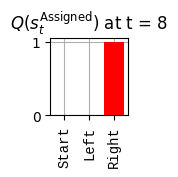

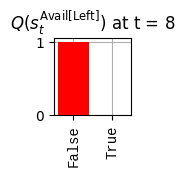

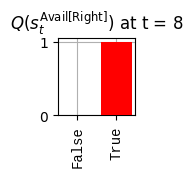

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


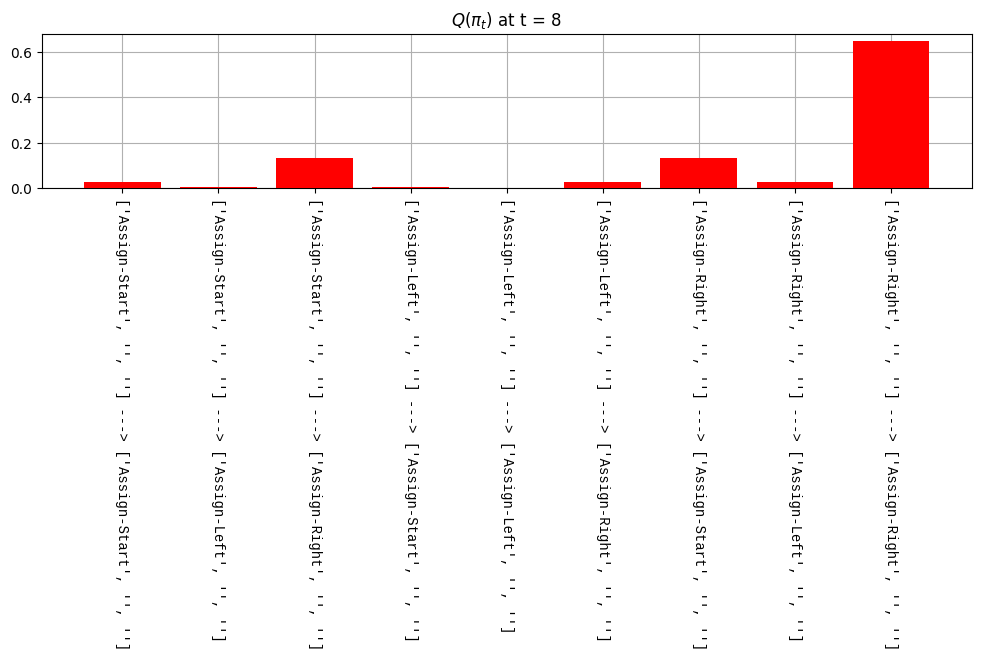

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss', 'Loss', 'Reward', 'Reward']}, 'oAvail': {'Left': [False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True]}}
Action at time 8: Assign-Right
sˣAvail[Left] at time 8: False
oRew[Left] at time 8: Null
oRew[

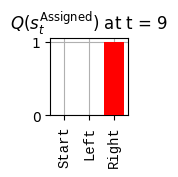

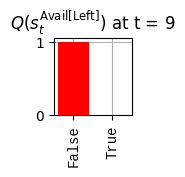

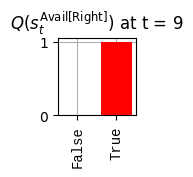

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


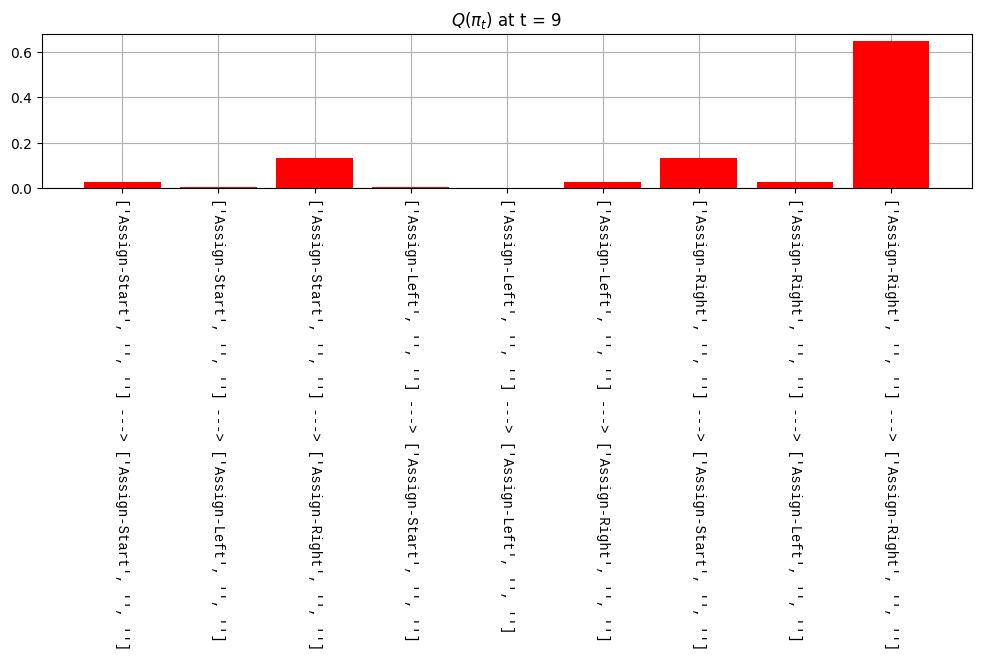

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss', 'Loss', 'Reward', 'Reward', 'Reward']}, 'oAvail': {'Left': [False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True]}}
Action at time 9: As

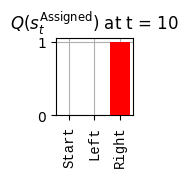

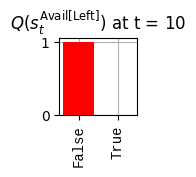

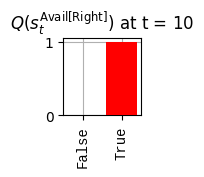

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


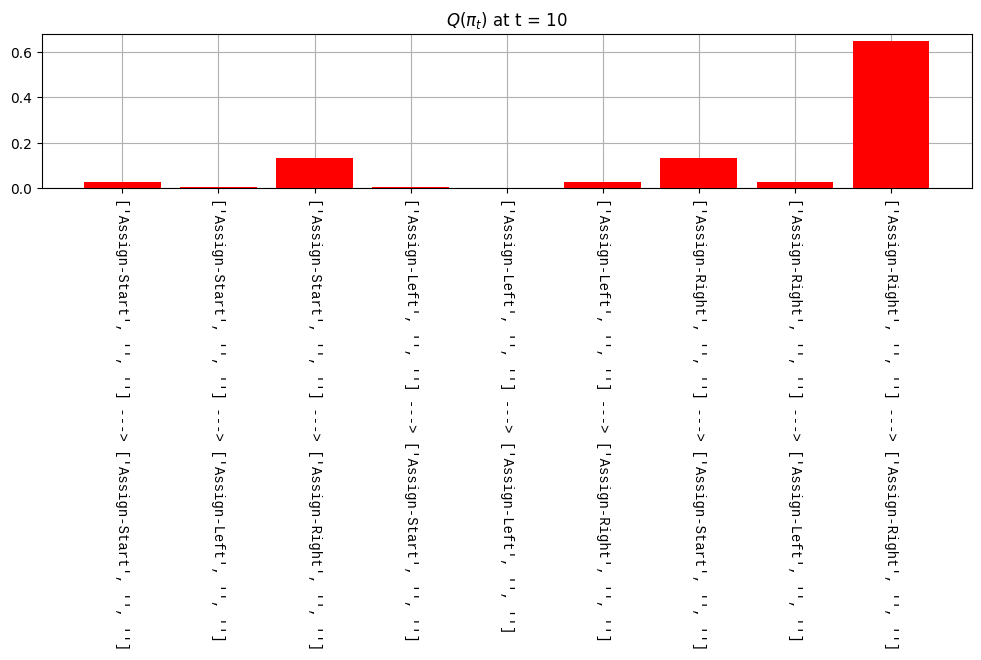

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss', 'Loss', 'Reward', 'Reward', 'Reward', 'Reward']}, 'oAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, Tr

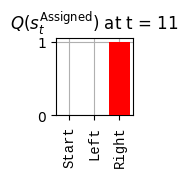

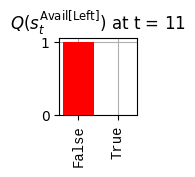

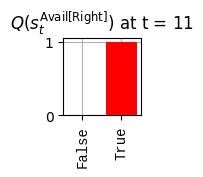

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


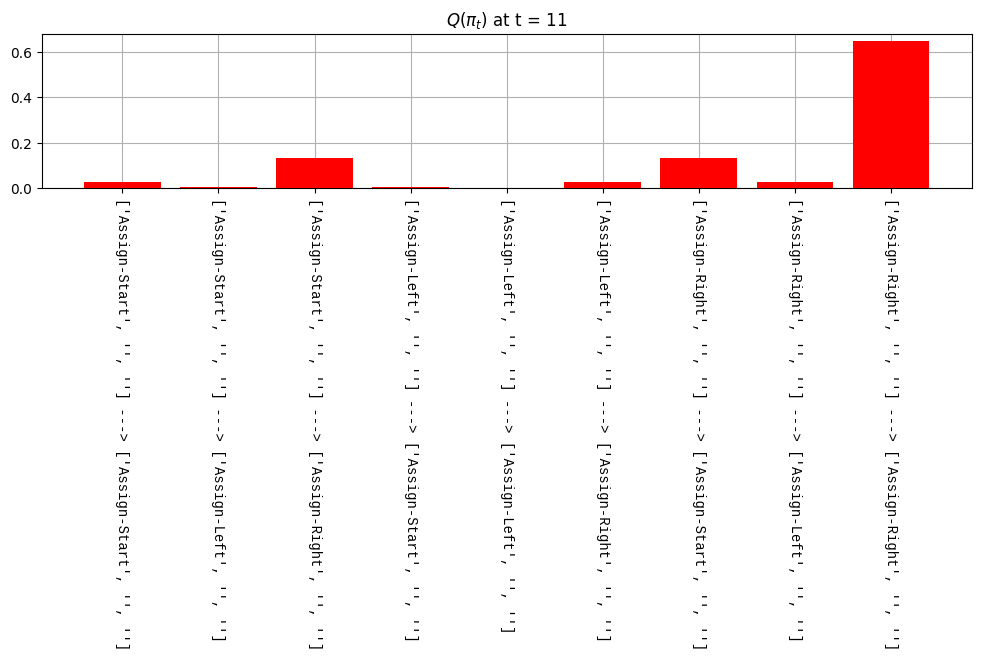

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss', 'Loss', 'Reward', 'Reward', 'Reward', 'Reward', 'Loss']}, 'oAvail': {'Left': [False, False, False, False, False, False, F

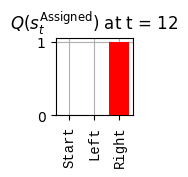

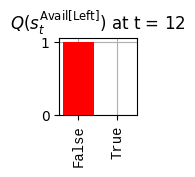

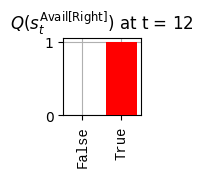

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QIpiI: 0.6499999761581421


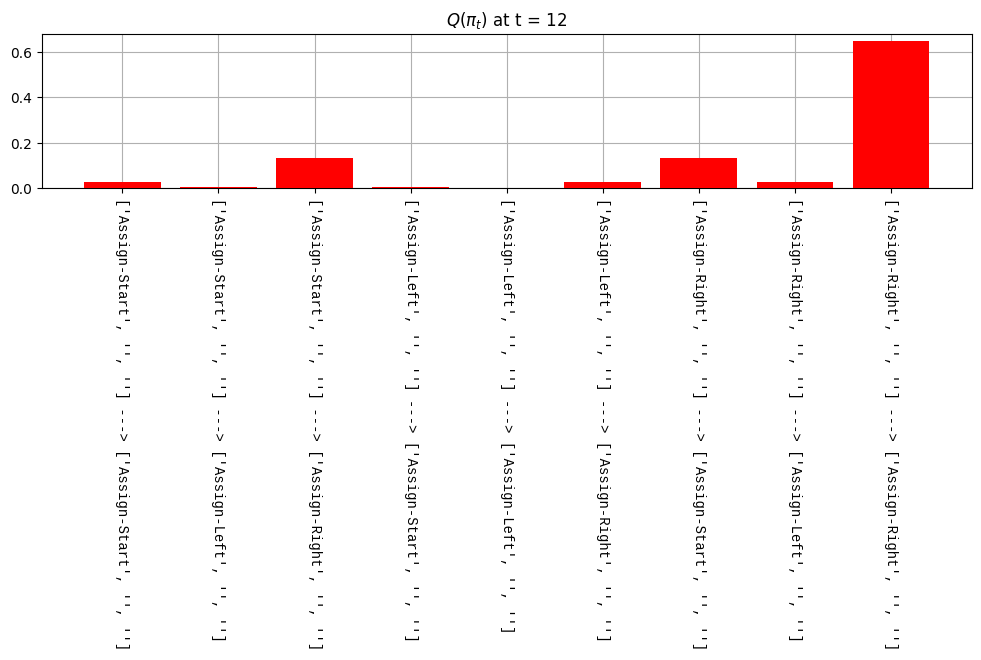

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss', 'Loss', 'Reward', 'Reward', 'Reward', 'Reward', 'Loss', 'Reward']}, 'o

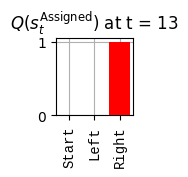

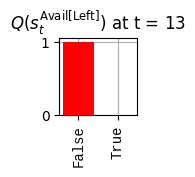

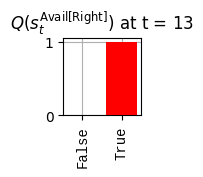

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)
np.max(QIpiI)=np.float32(0.6475842)
BEST QI

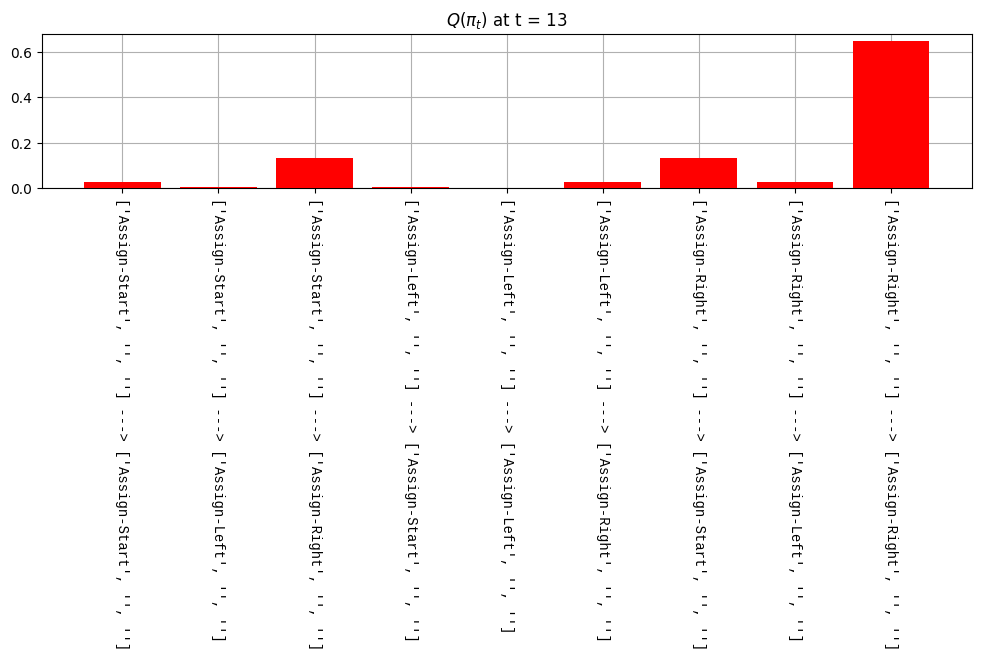

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Loss', 'Reward', 'Reward', 'Loss', 'Loss', 'Reward', '

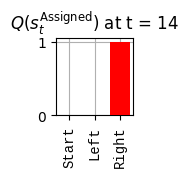

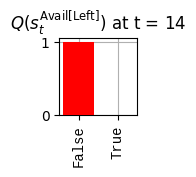

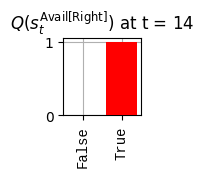

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 0.13 0.03 0.65]
np.argmax(QIpiI)=np.int64(8)

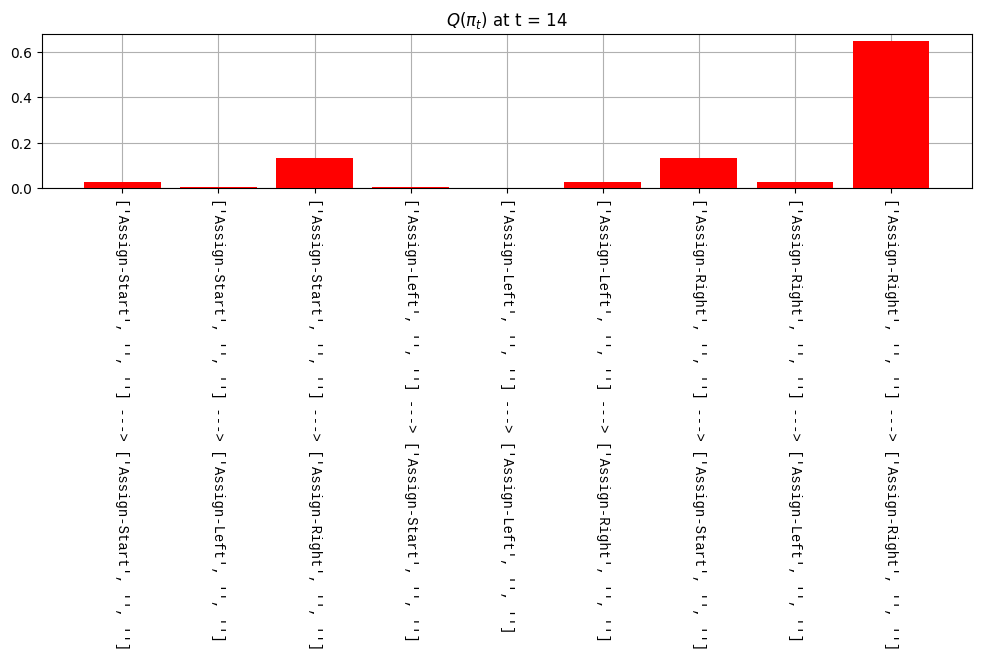

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'], 'Right': ['Loss', 'Reward', 'Los

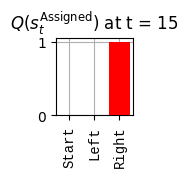

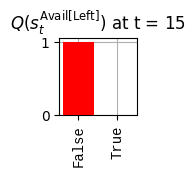

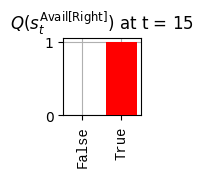

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIpiI)=9
QIpiI: [0.03 0.01 0.13 0.01 0.   0.03 

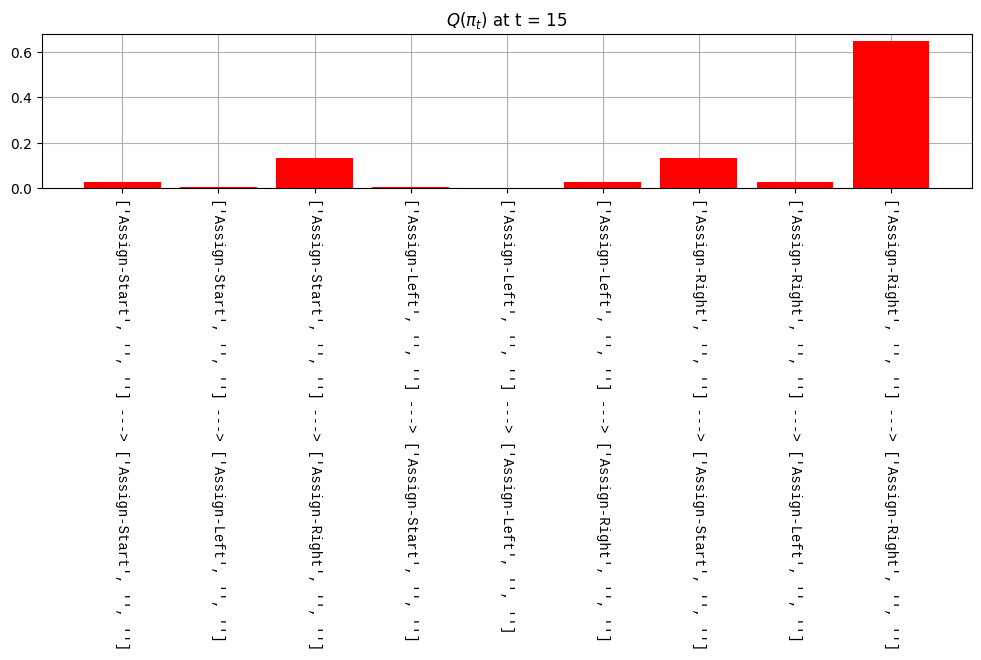

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null'

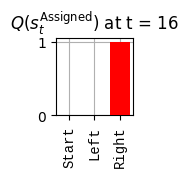

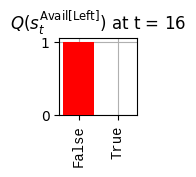

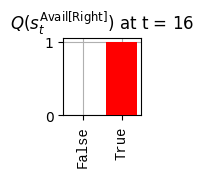

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)
LOWEST EFE in 8: -3.1999998092651367
len(QIp

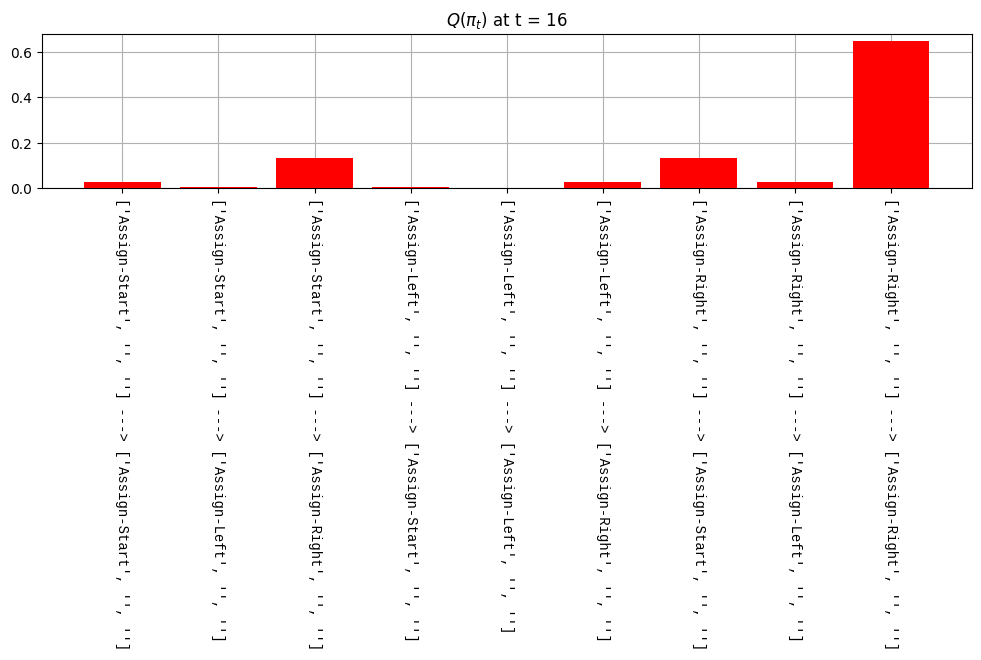

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Null', 'Nu

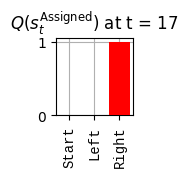

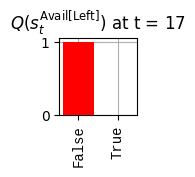

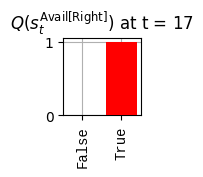

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.int64(8)
np.min(EFE)=np.float32(-3.1999998)


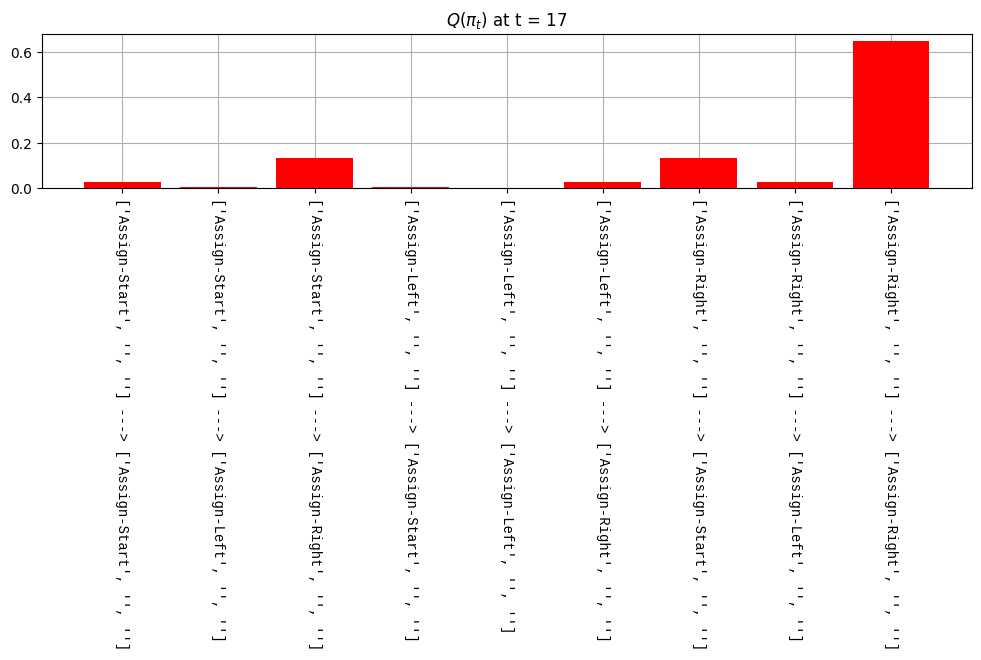

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'oRew': {'Left': ['Null', 'Null', 'Null', 

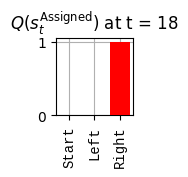

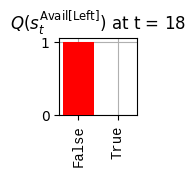

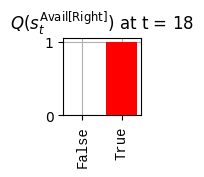

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%% Policies %%%
len(EFE)=9
np.argmin(EFE)=np.

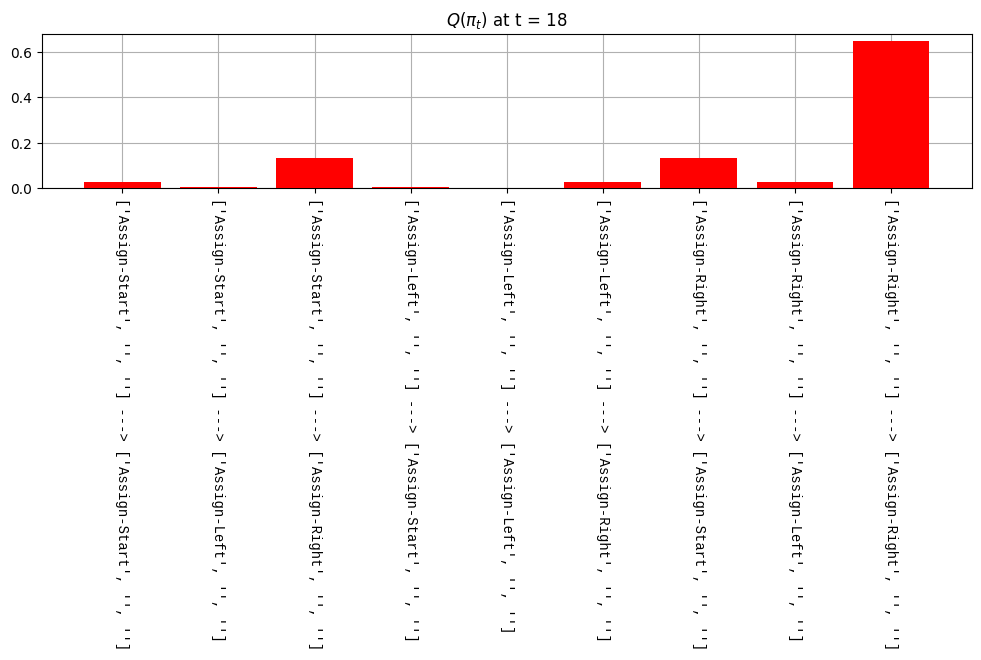

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'],

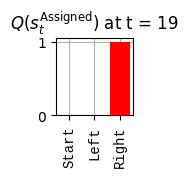

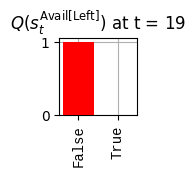

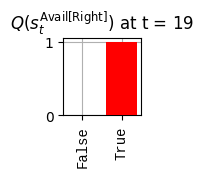

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
	%%

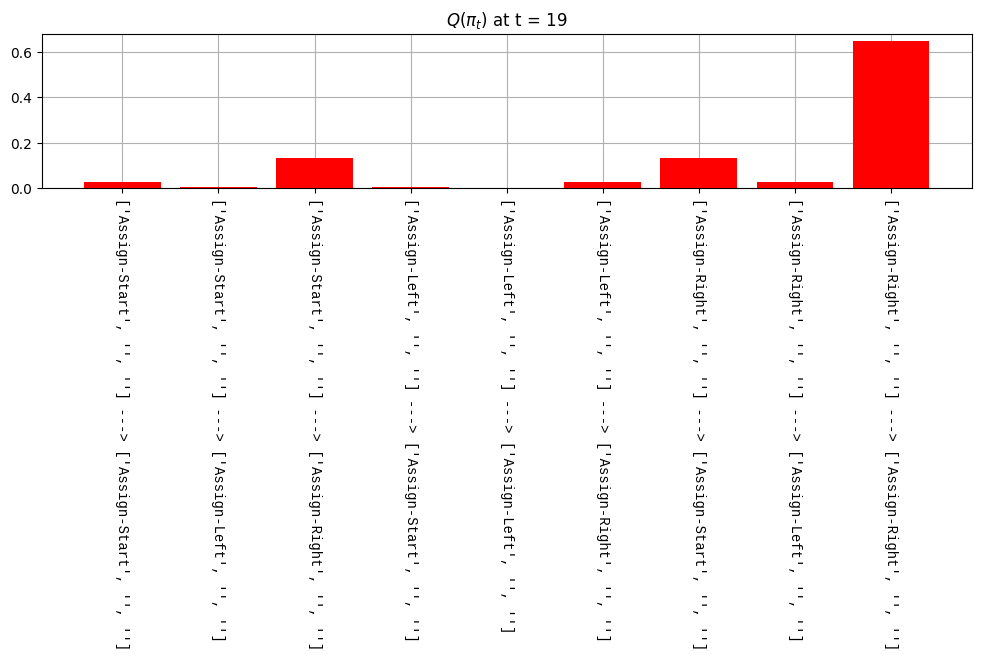

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'R

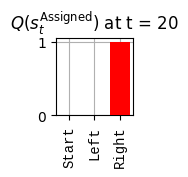

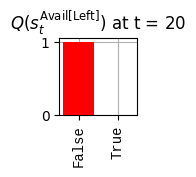

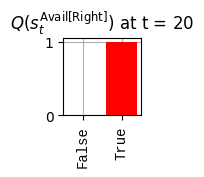

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, Tru

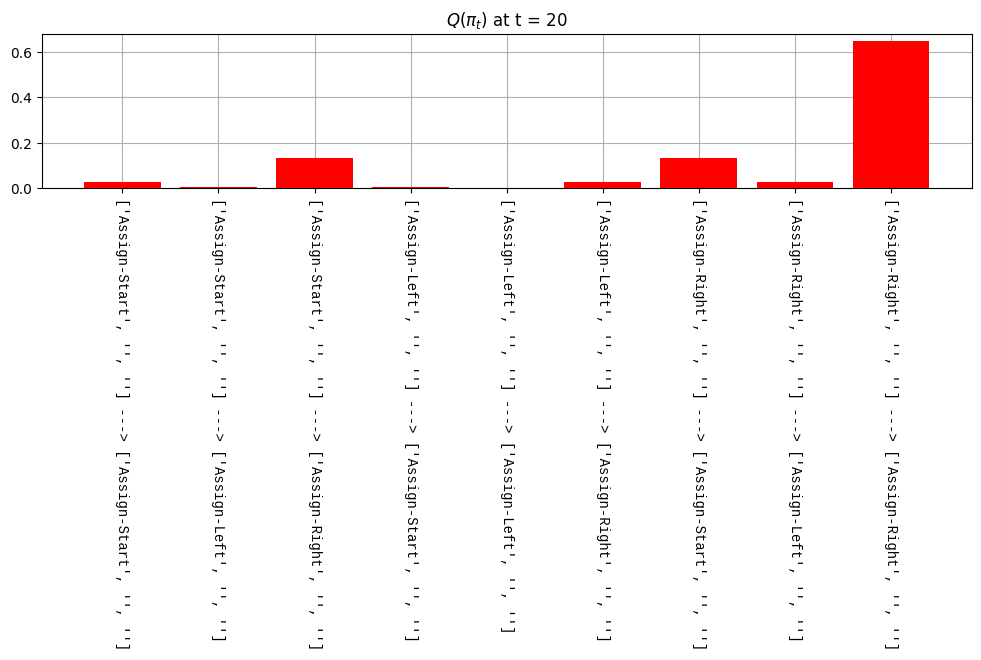

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Rig

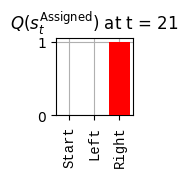

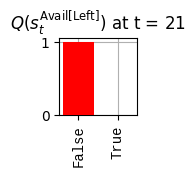

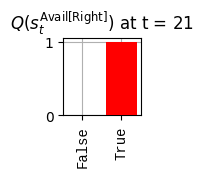

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, T

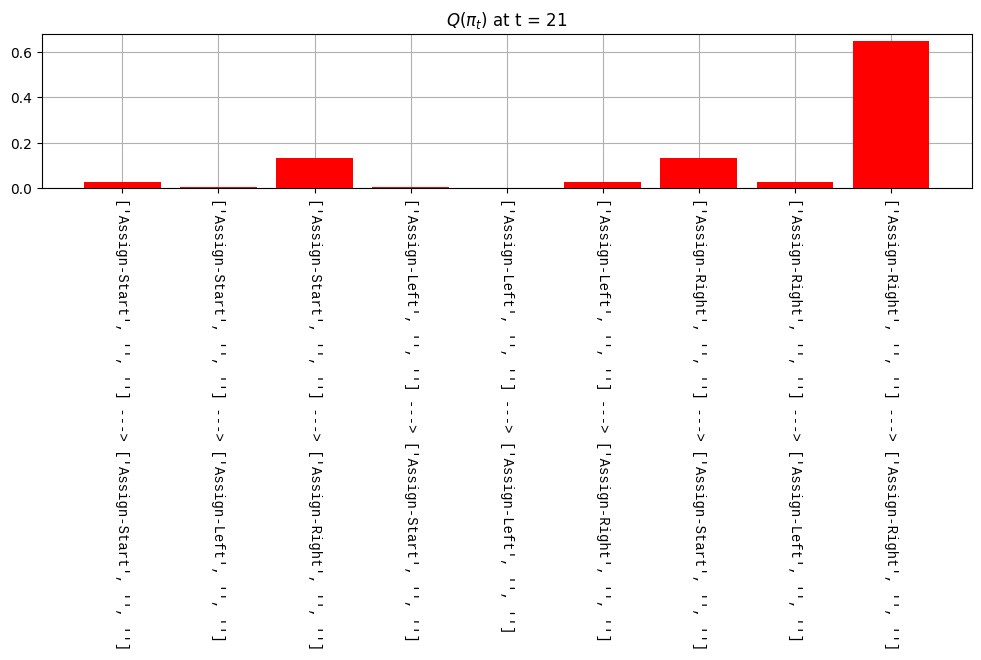

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right

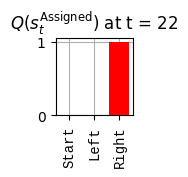

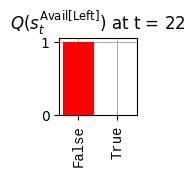

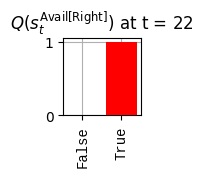

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True,

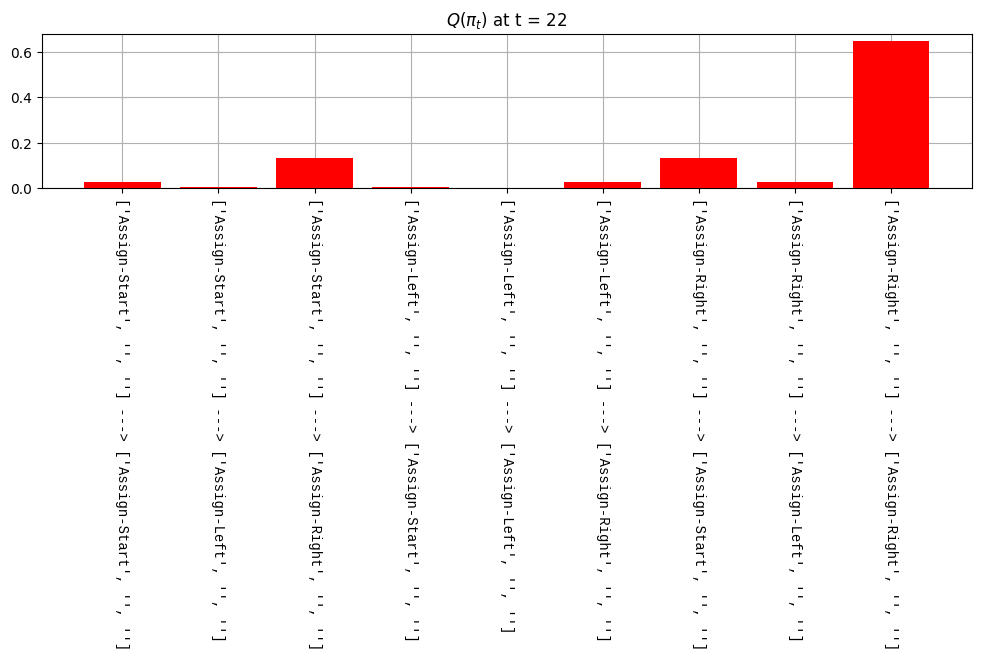

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['Right', 'Right', 'Right', 'Right',

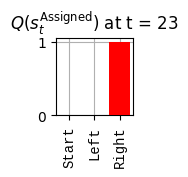

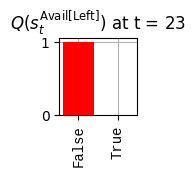

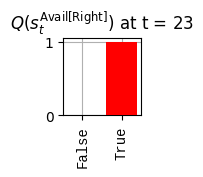

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False

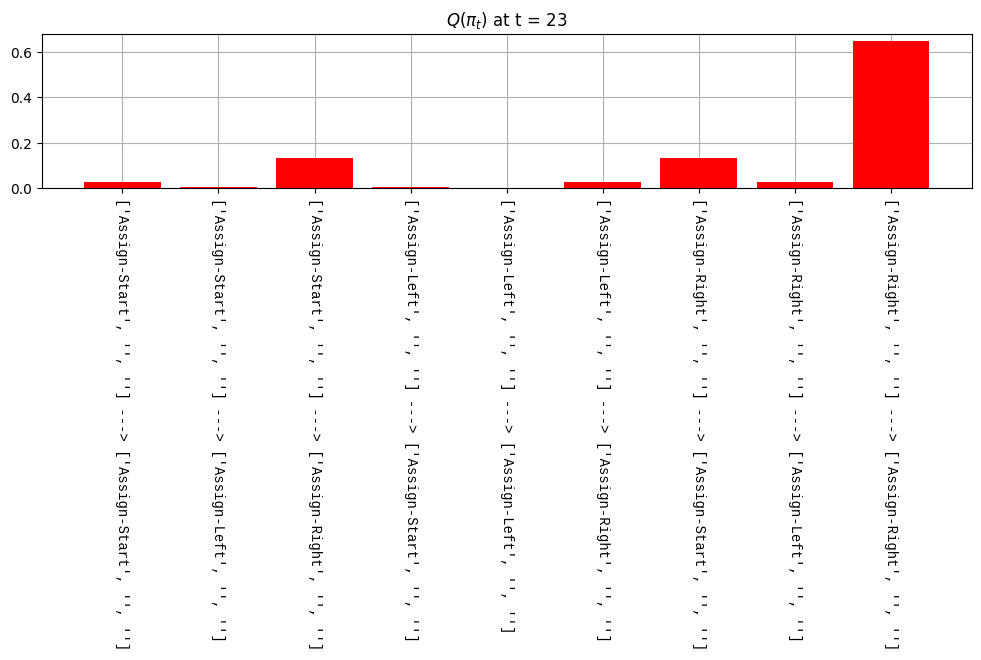

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assign-Right')
o_mods:
{'oAssigned': ['

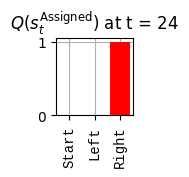

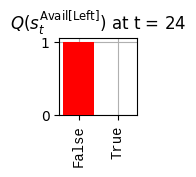

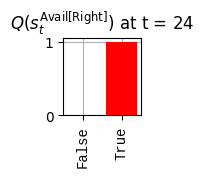

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, Fa

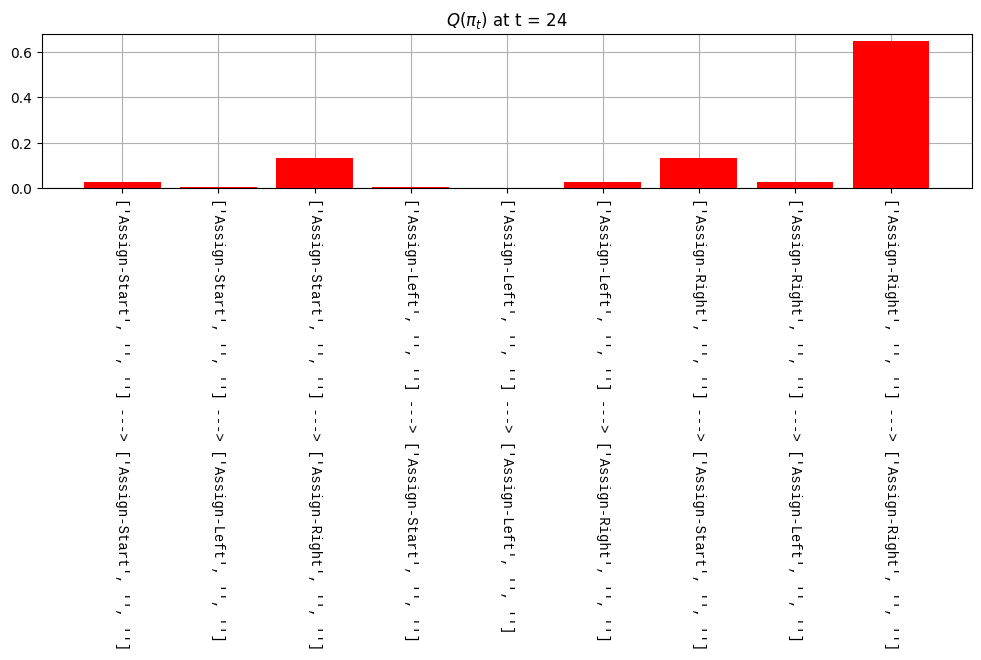

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
### NEXT OBSERVE ###
=== step('Assig

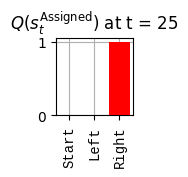

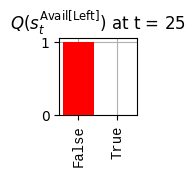

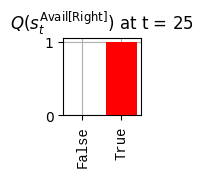

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False,

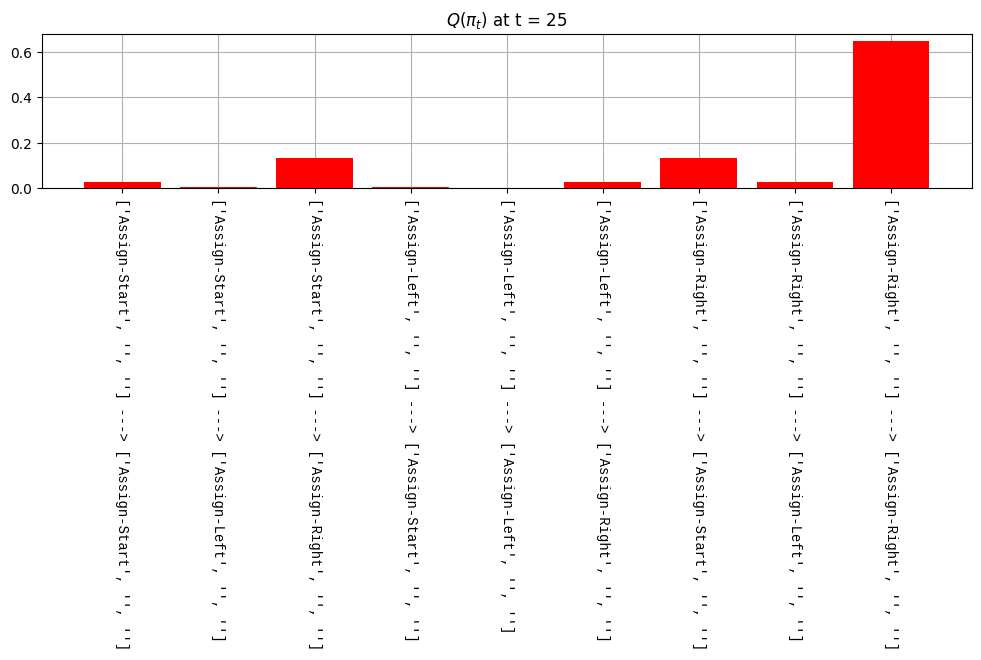

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2']}
##

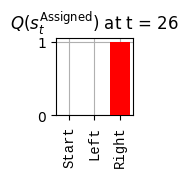

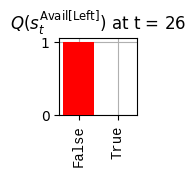

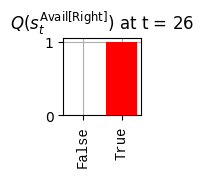

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, False, False, False, False, Fal

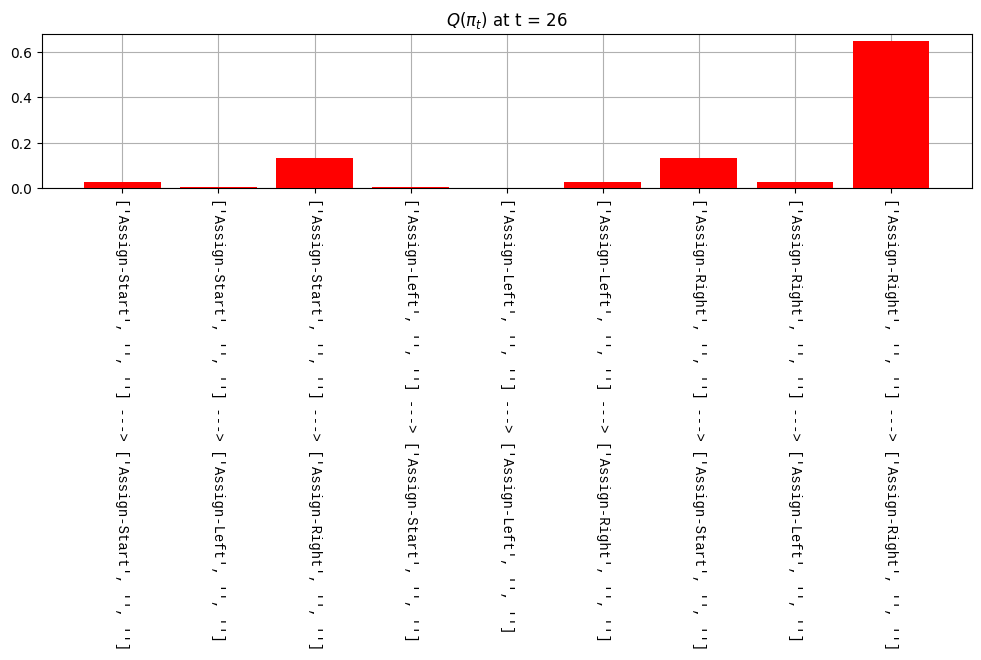

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null

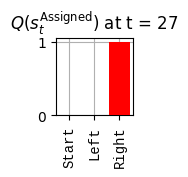

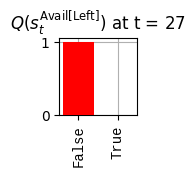

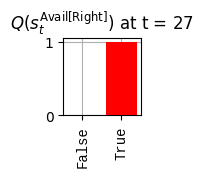

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left': [False, False, False, False, 

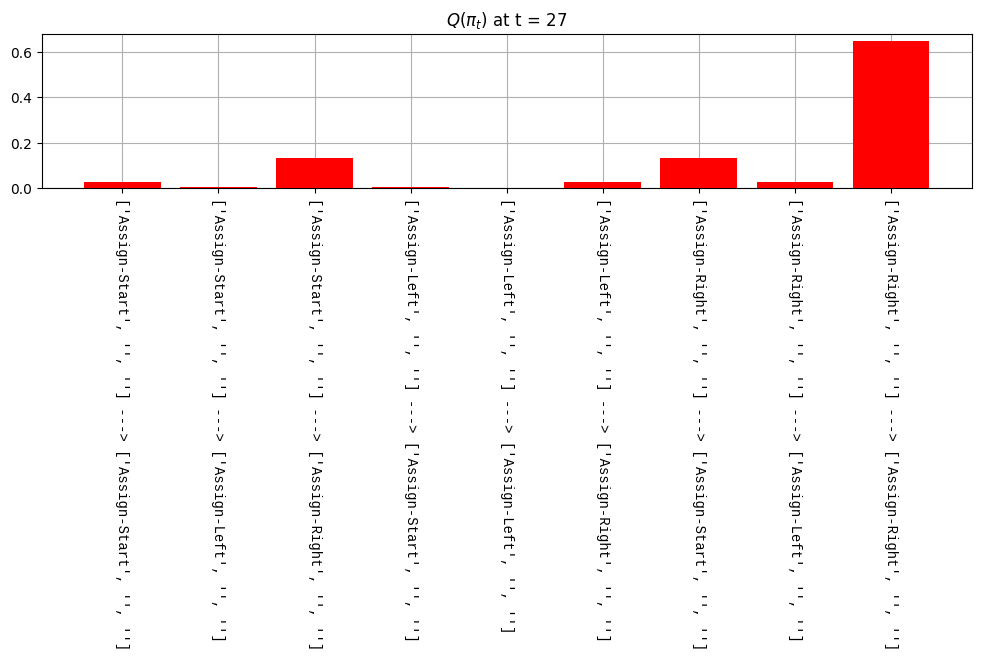

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2'

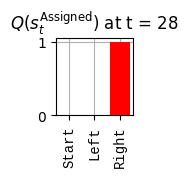

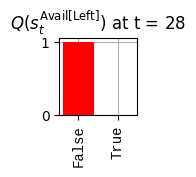

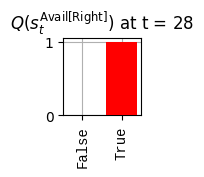

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sˣAvail': {'Left'

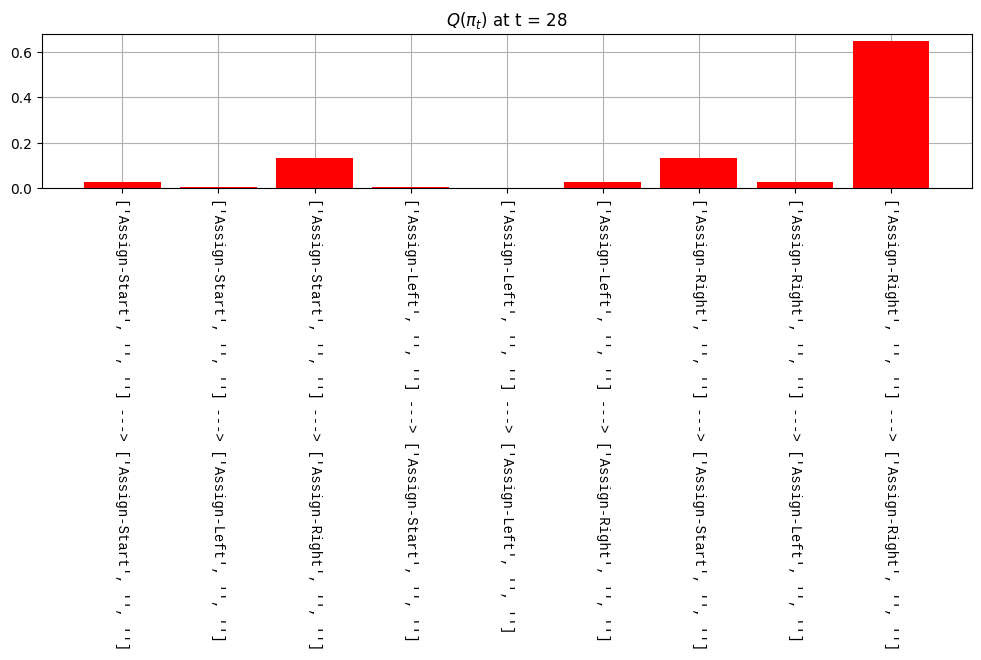

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 

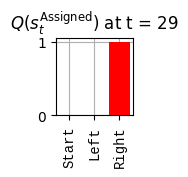

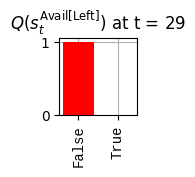

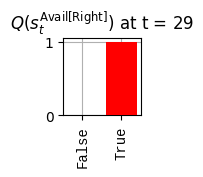

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right

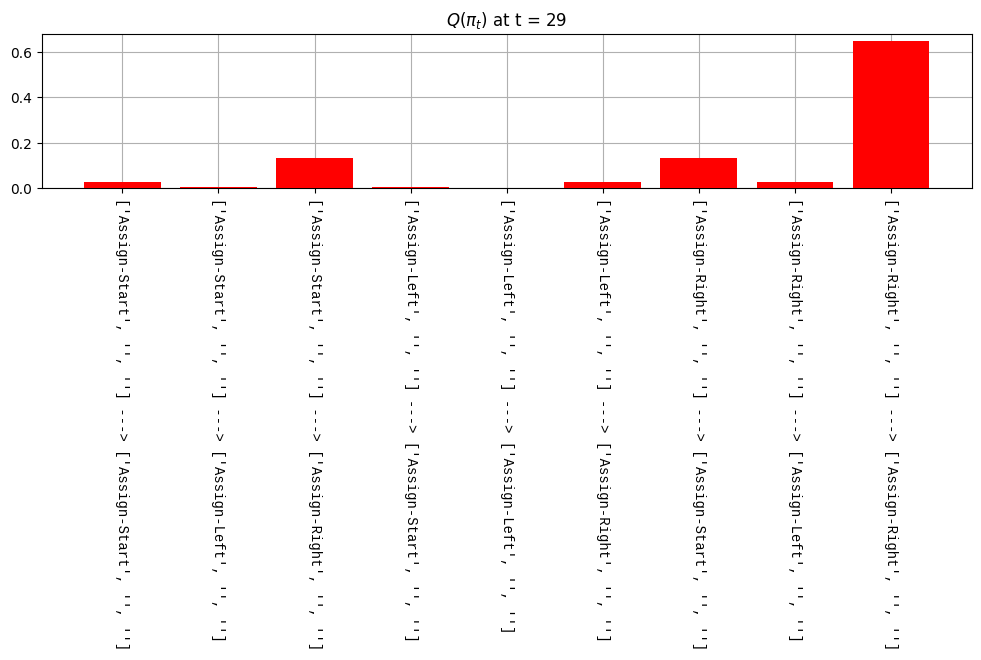

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'N

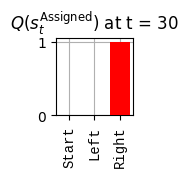

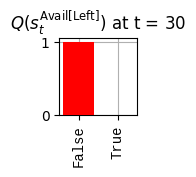

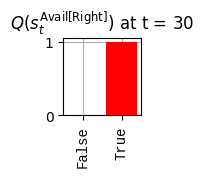

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'R

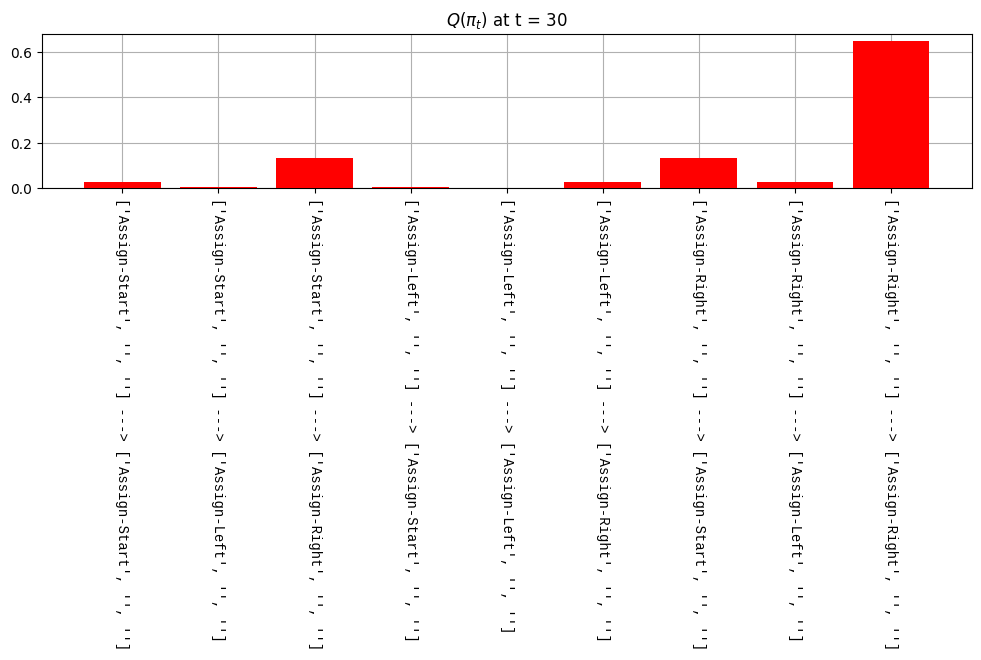

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Nul

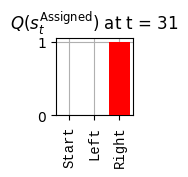

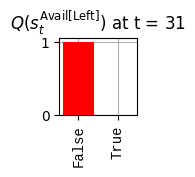

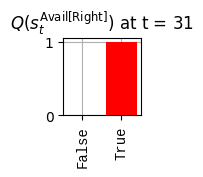

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'

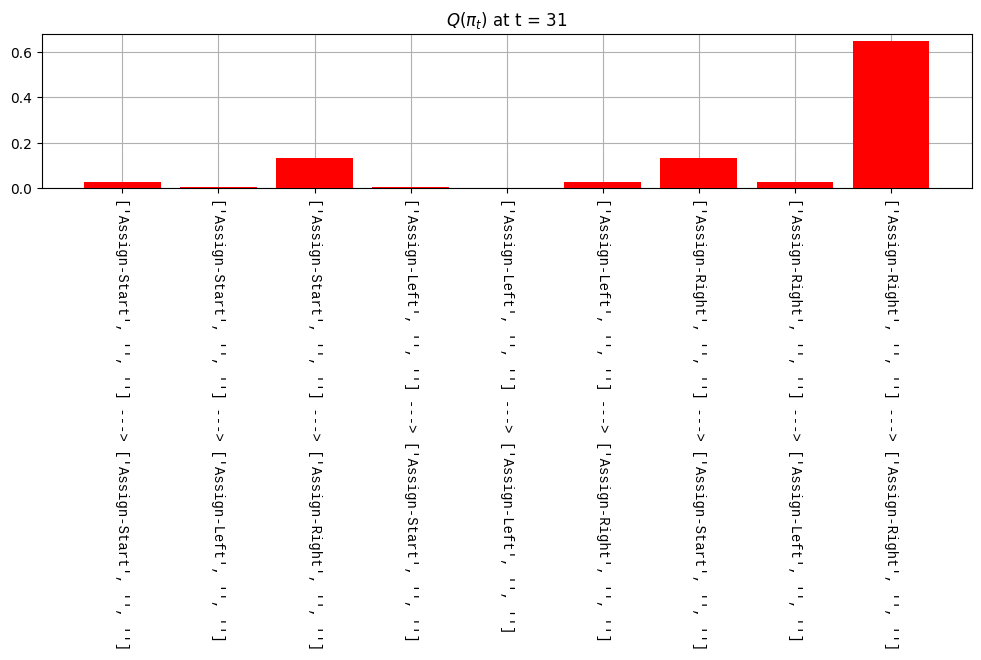

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2

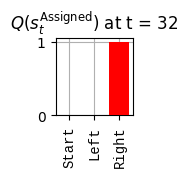

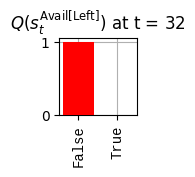

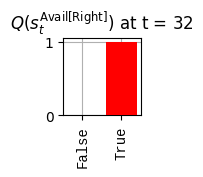

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Ri

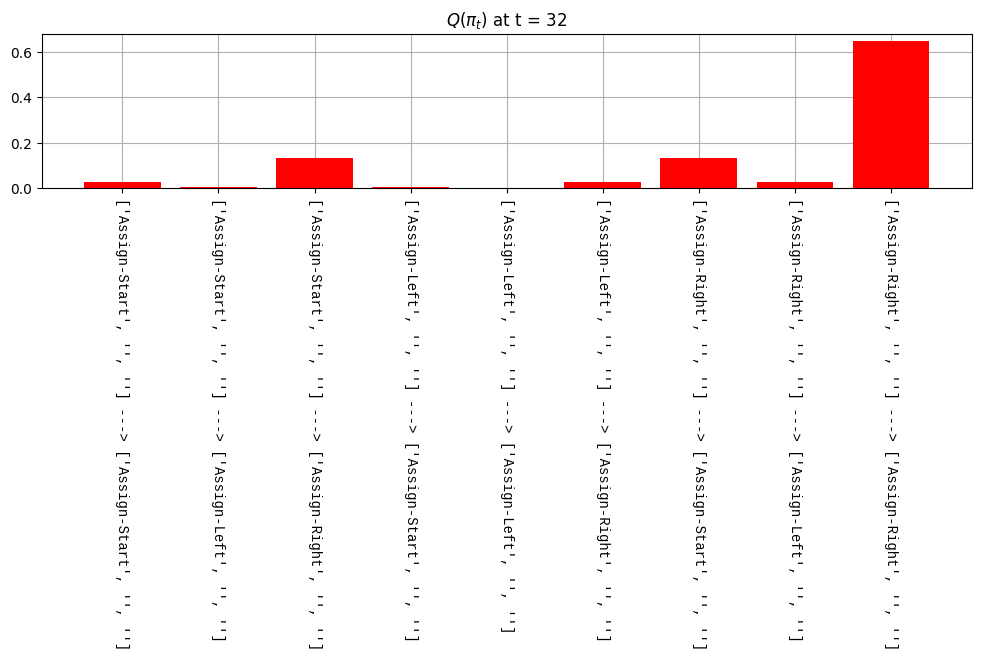

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2', 'Null2',

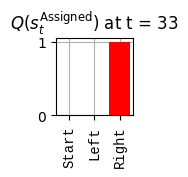

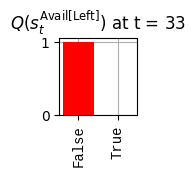

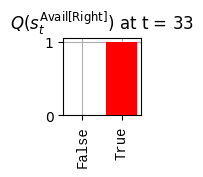

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right',

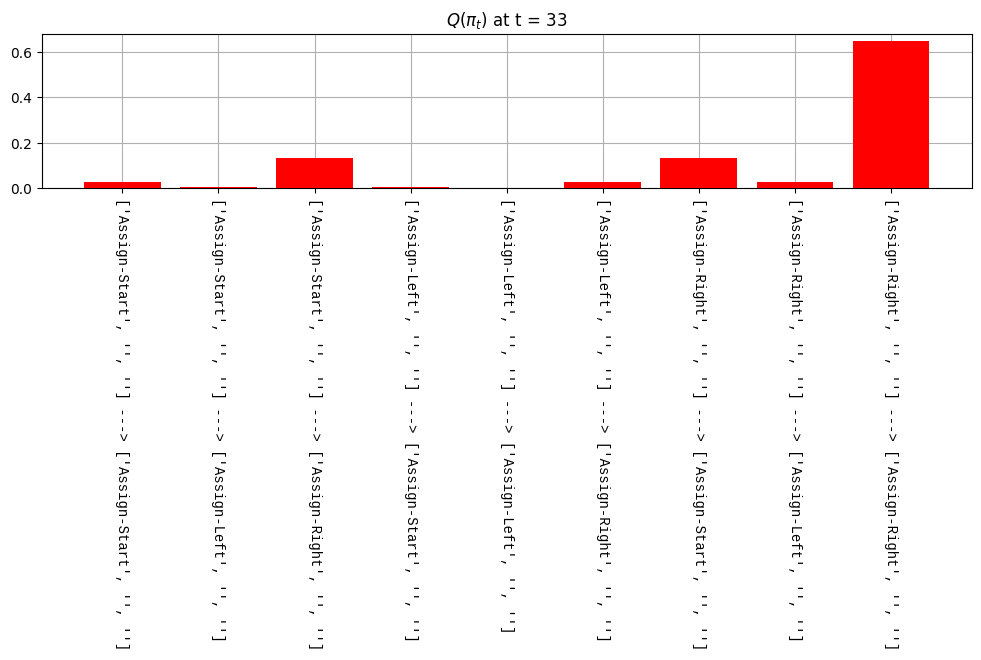

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Null2', 'Null2', 'Null2', '

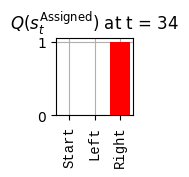

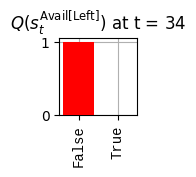

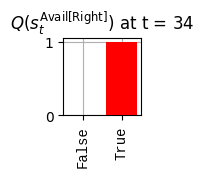

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Rig

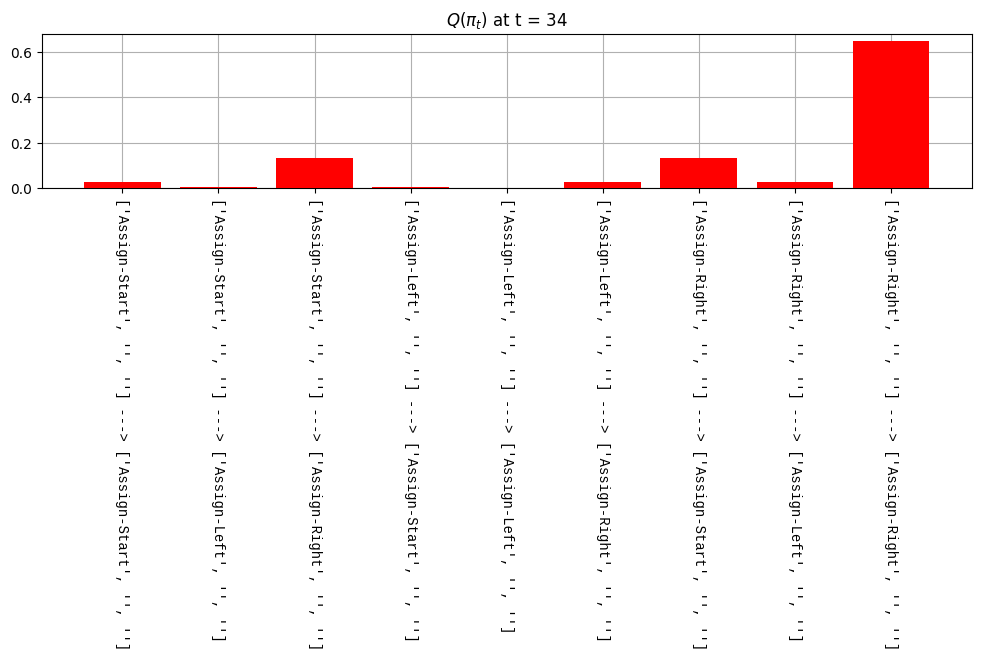

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'], 'aNull2': ['Null2', 'Nu

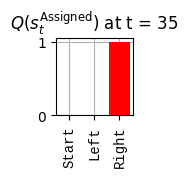

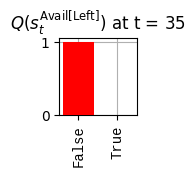

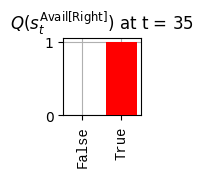

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 

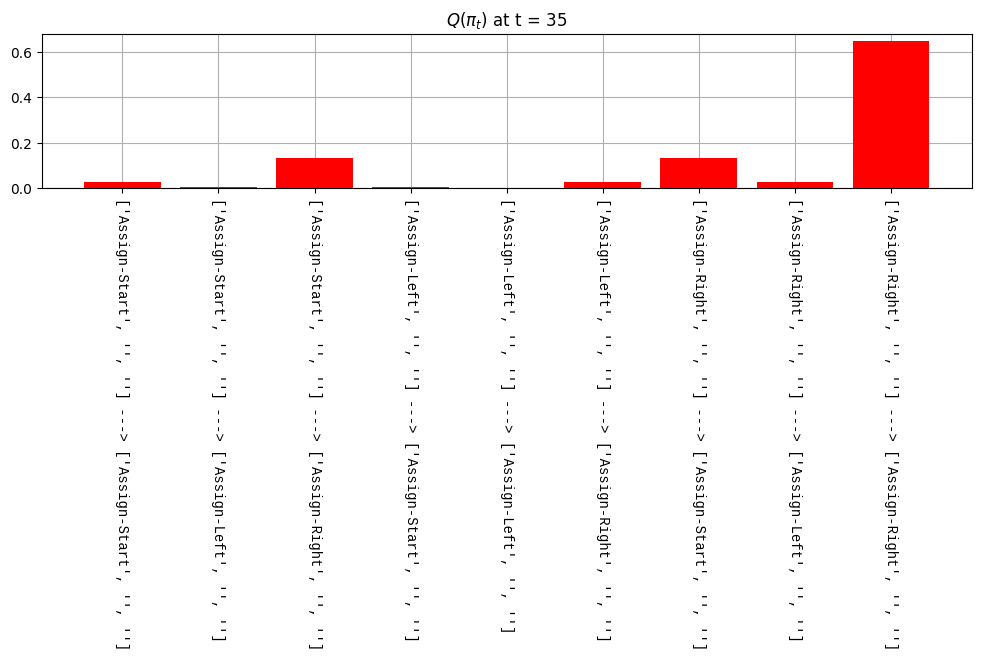

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1']

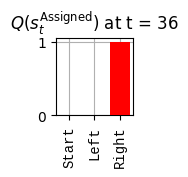

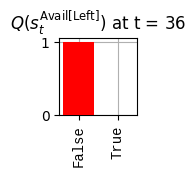

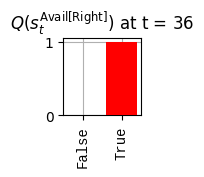

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Righ

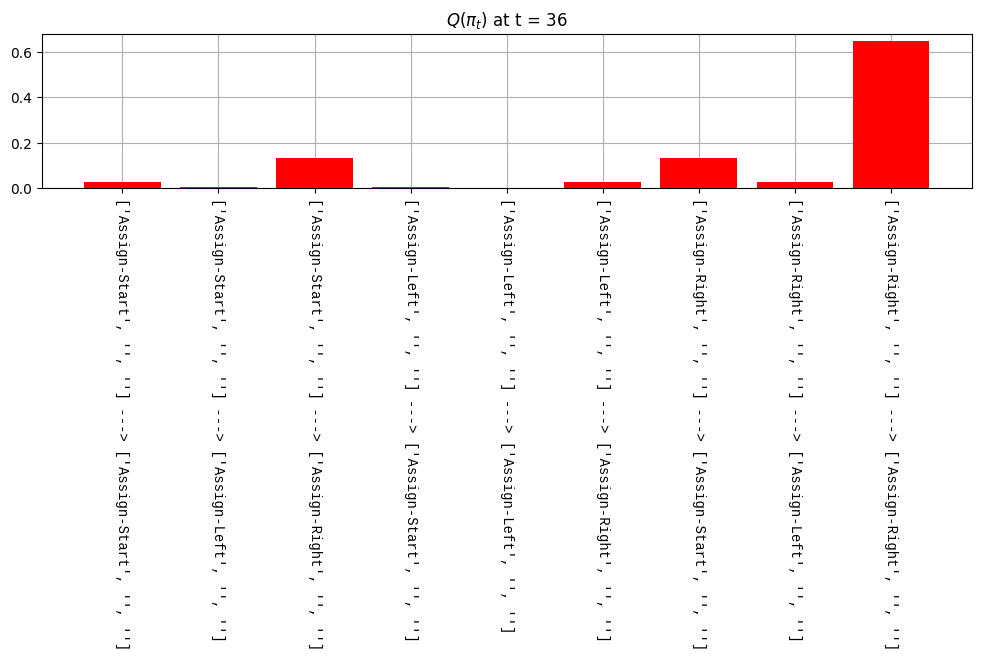

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', '

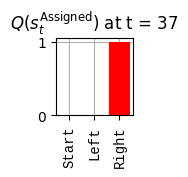

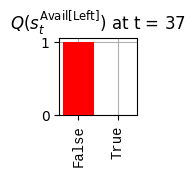

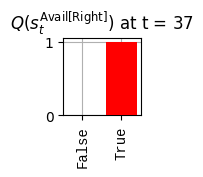

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', '

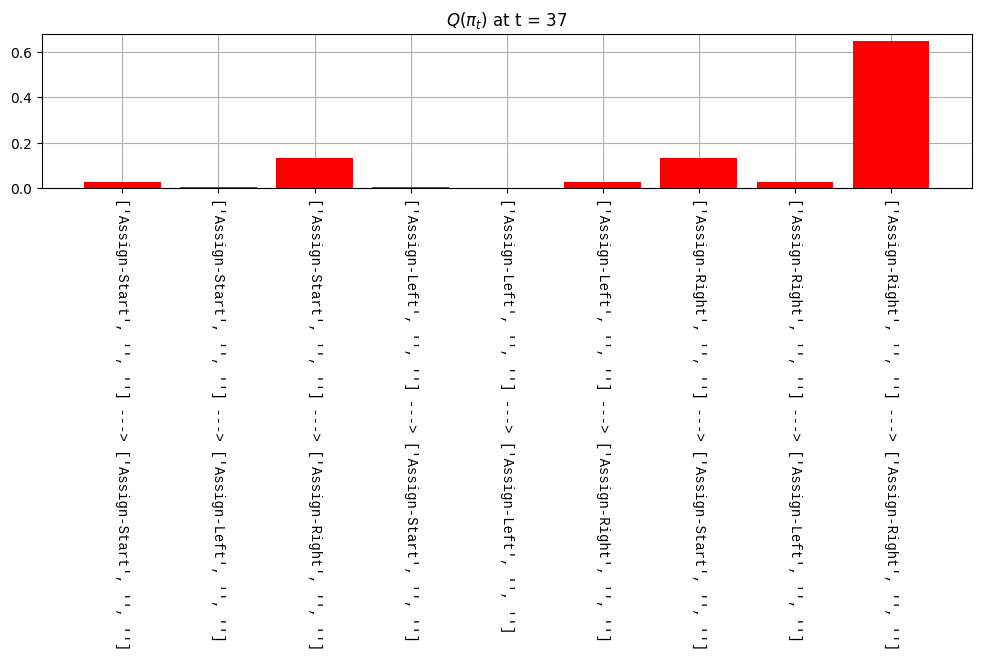

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Nu

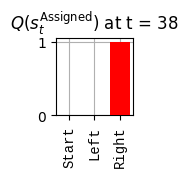

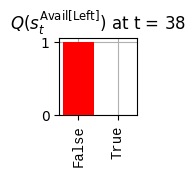

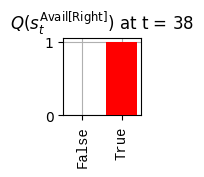

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right

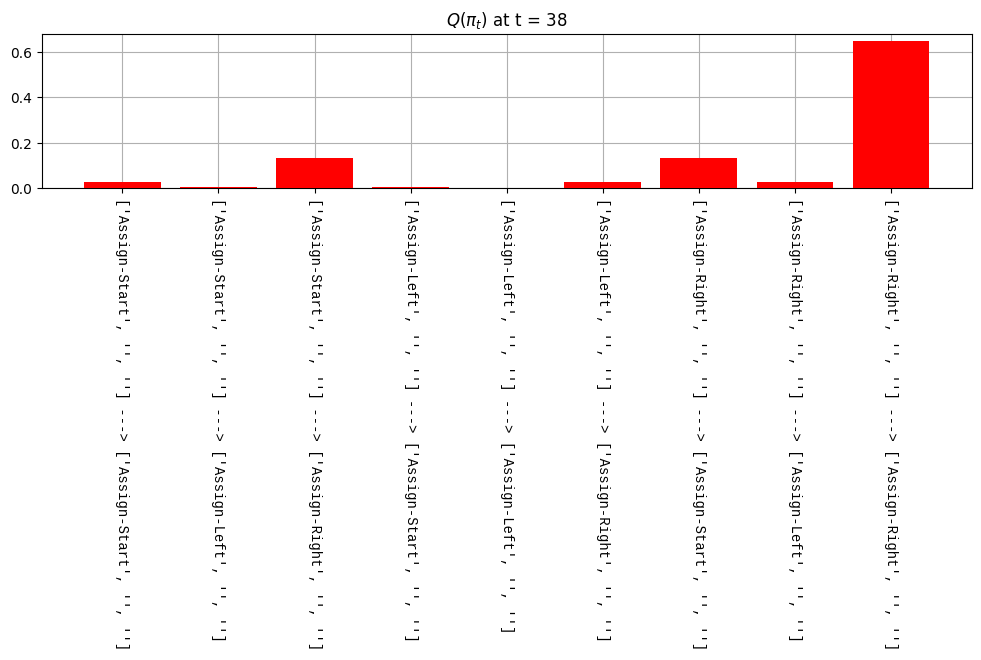

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null

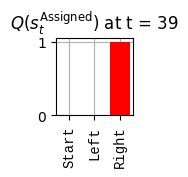

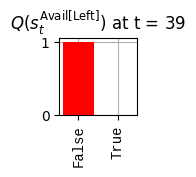

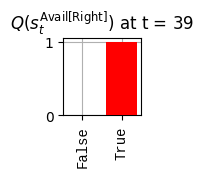

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right', 'Right', 'Right', 'R

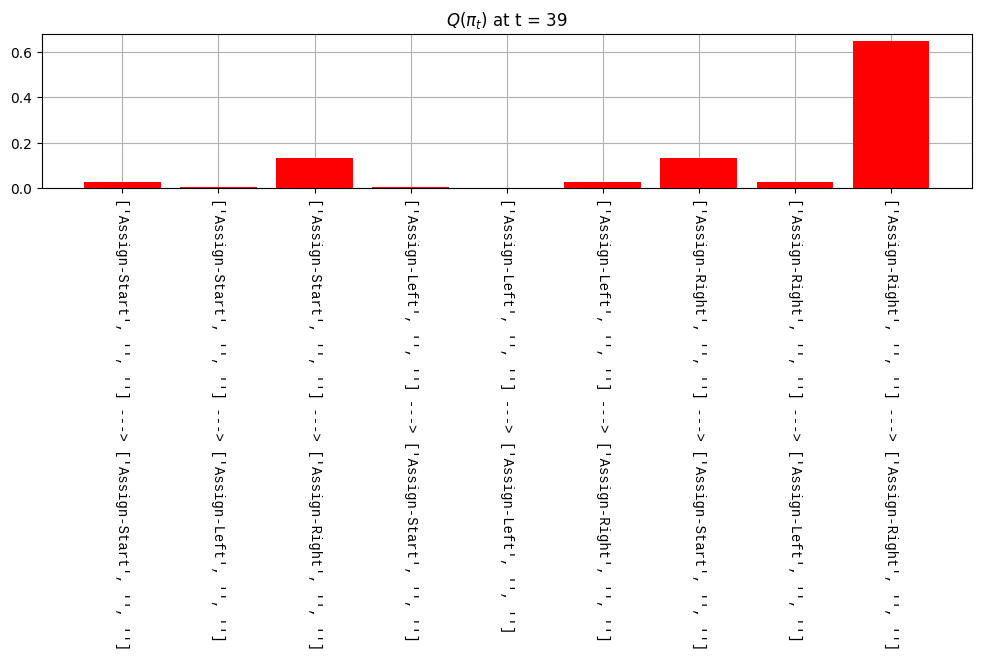

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'

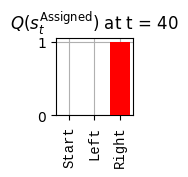

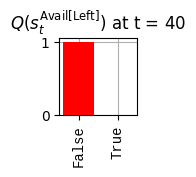

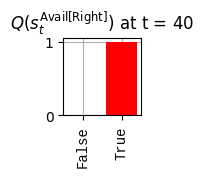

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssigned': ['Start', 'Right'

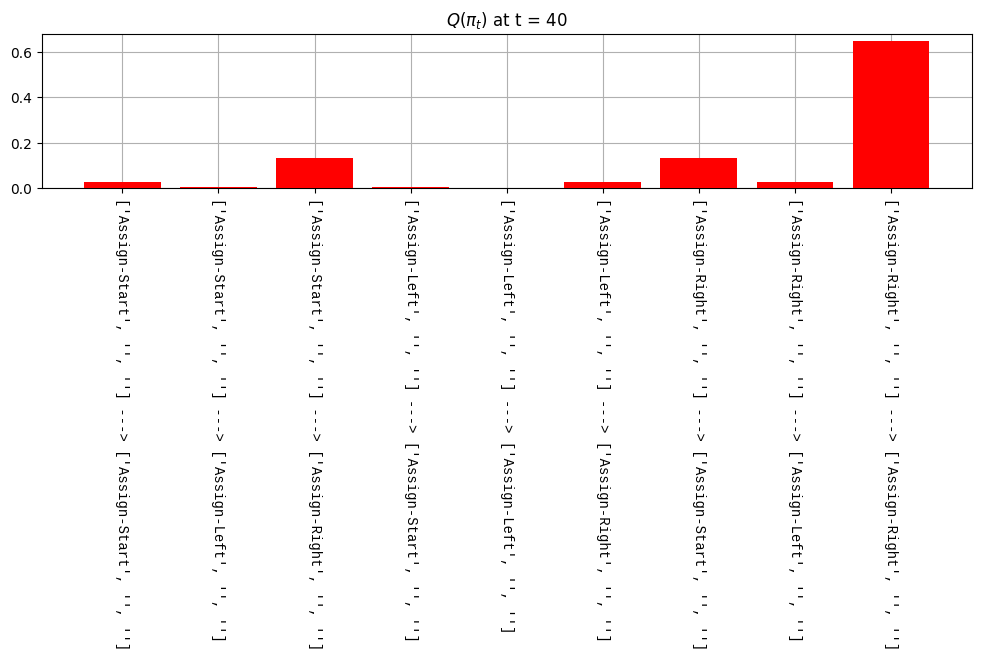

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 

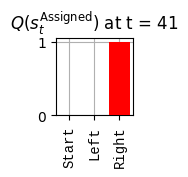

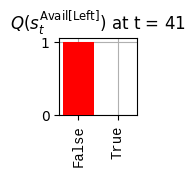

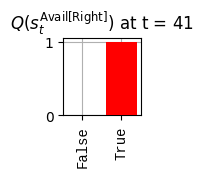

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]}}
sˣ_facs:
{'sˣAssign

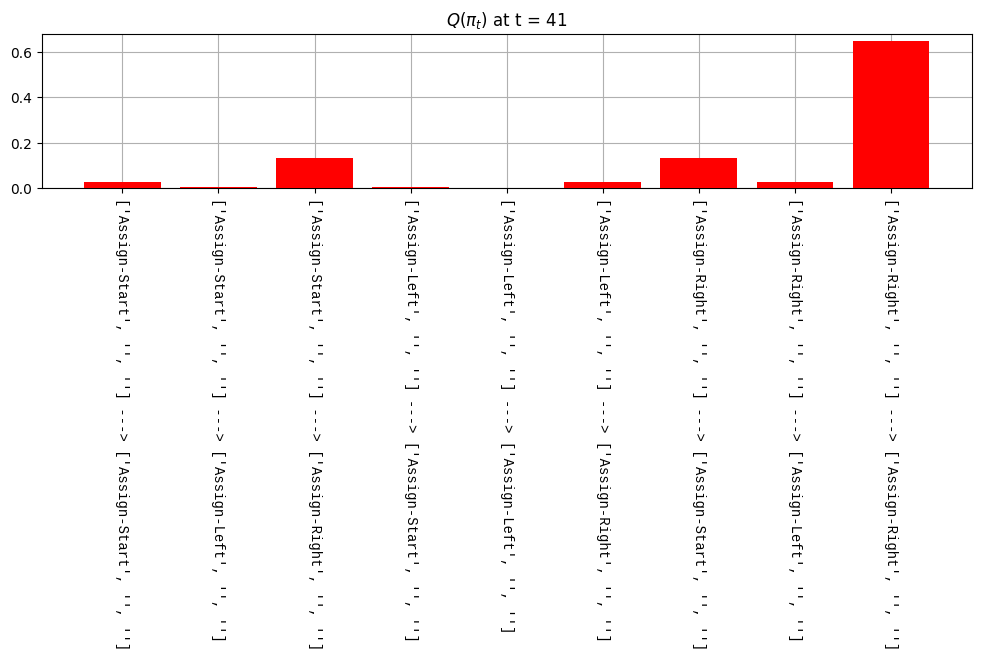

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'N

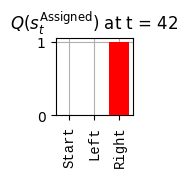

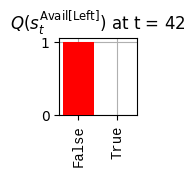

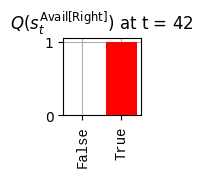

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]

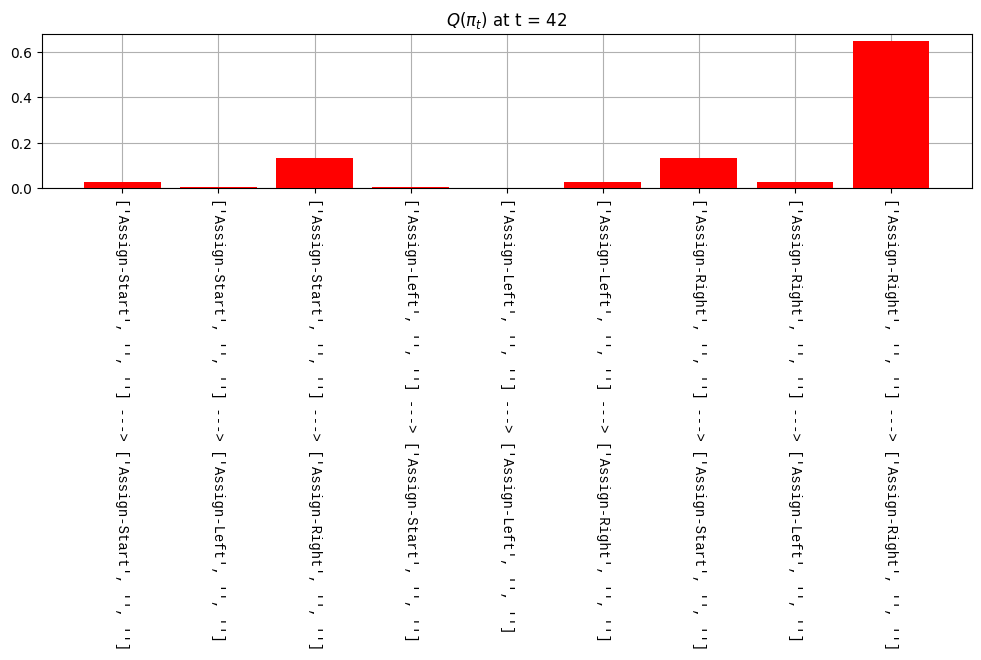

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Nul

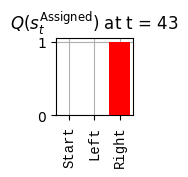

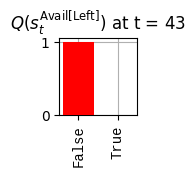

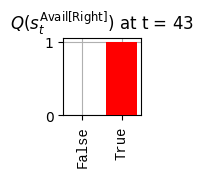

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, T

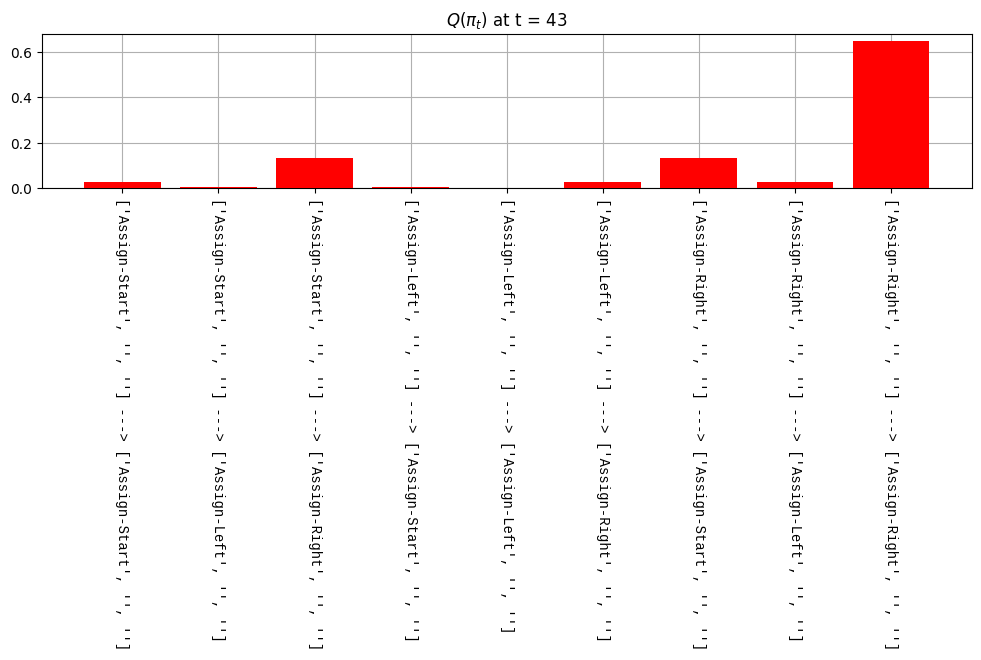

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1

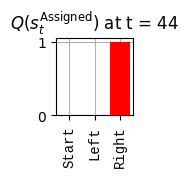

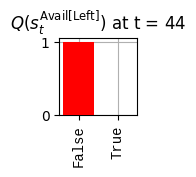

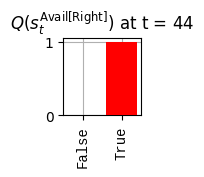

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, Tru

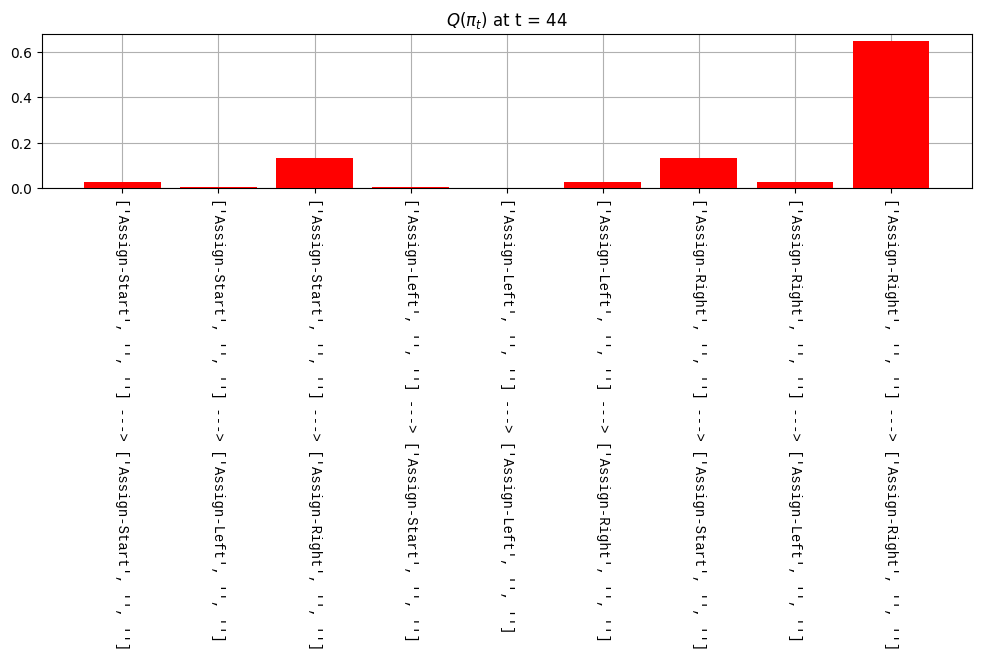

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1',

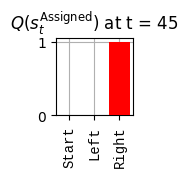

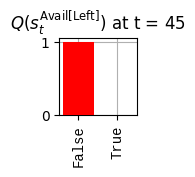

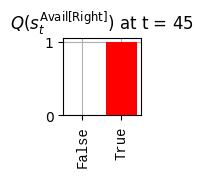

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True,

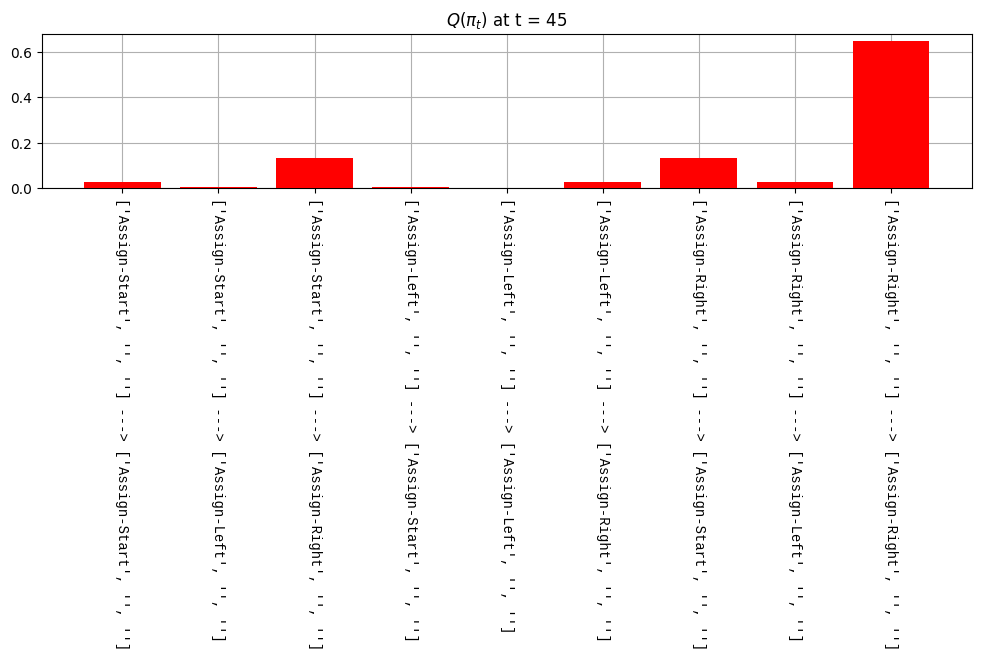

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', '

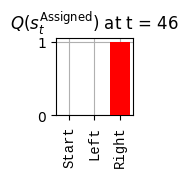

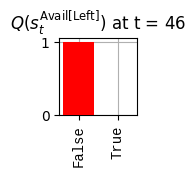

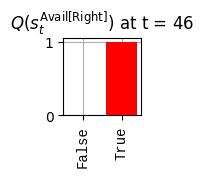

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, T

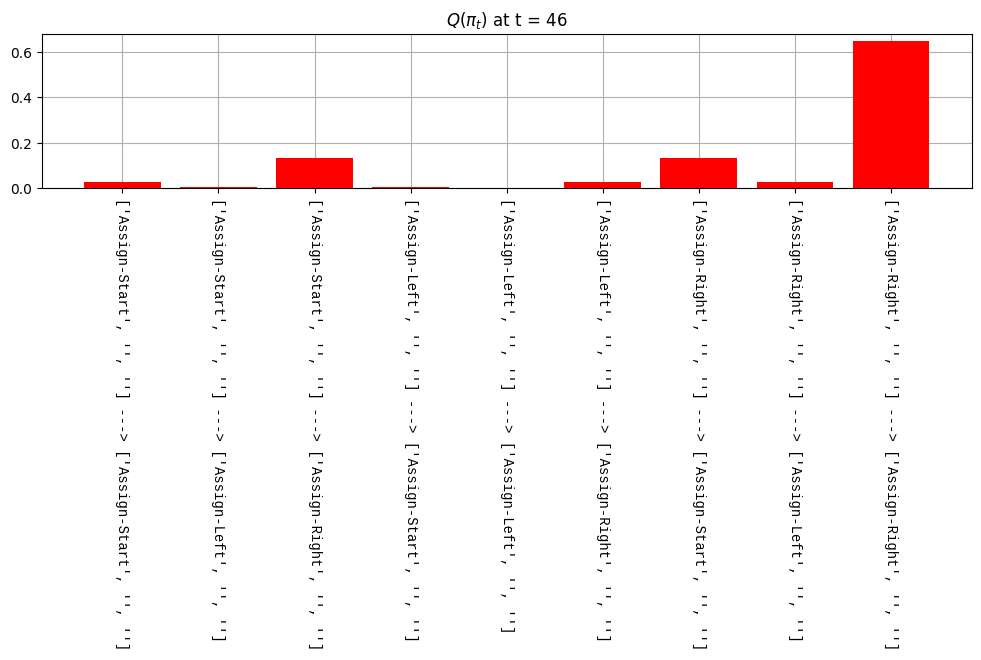

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Nu

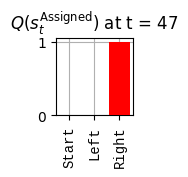

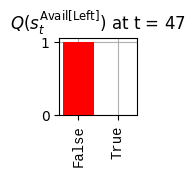

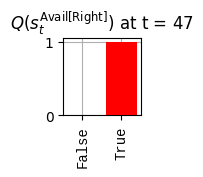

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, Tru

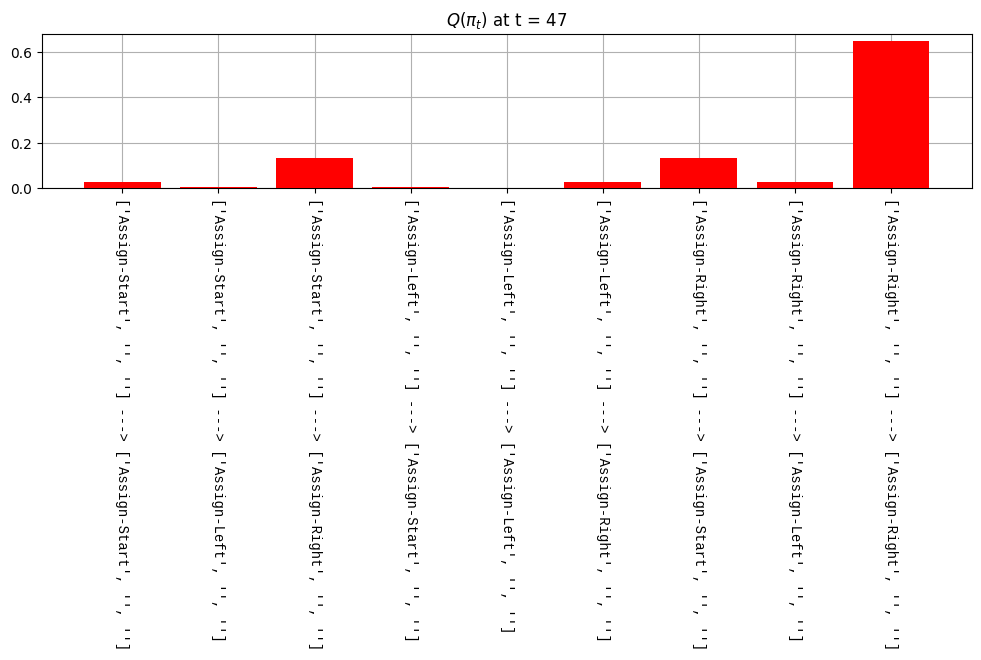

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null

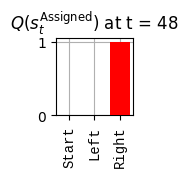

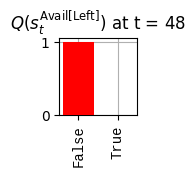

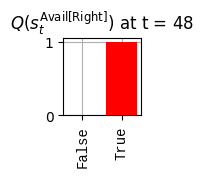

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True,

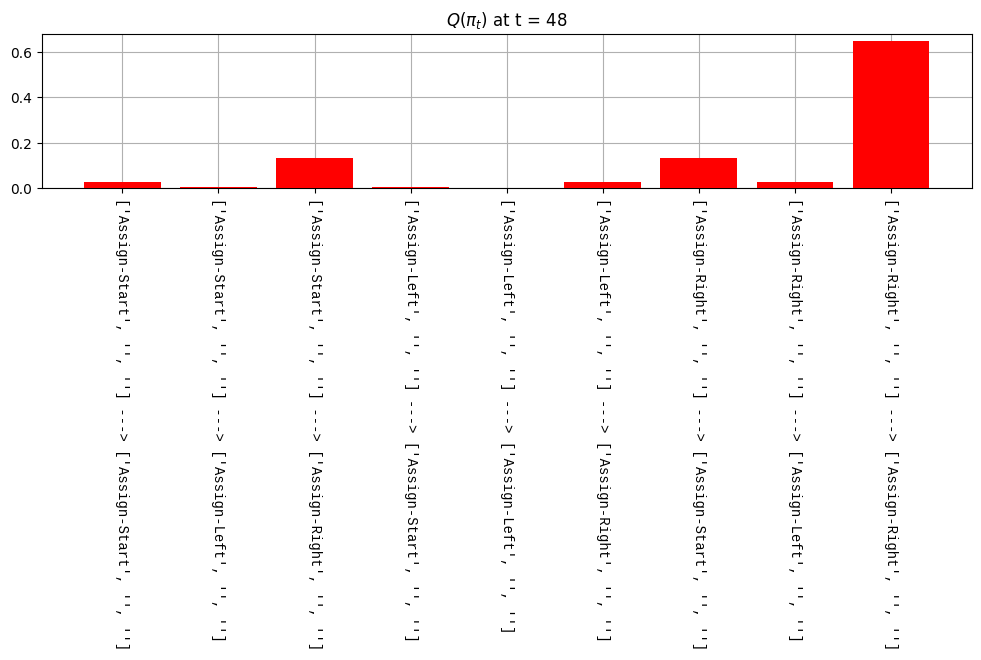

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1'

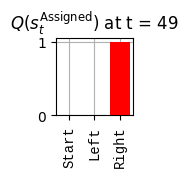

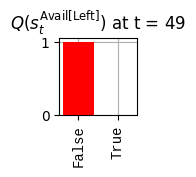

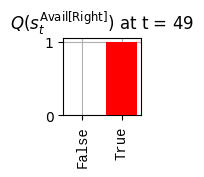

s_facs:
{'sAssigned': ['Start', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right', 'Right'], 'sAvail': {'Left': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'Right': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, T

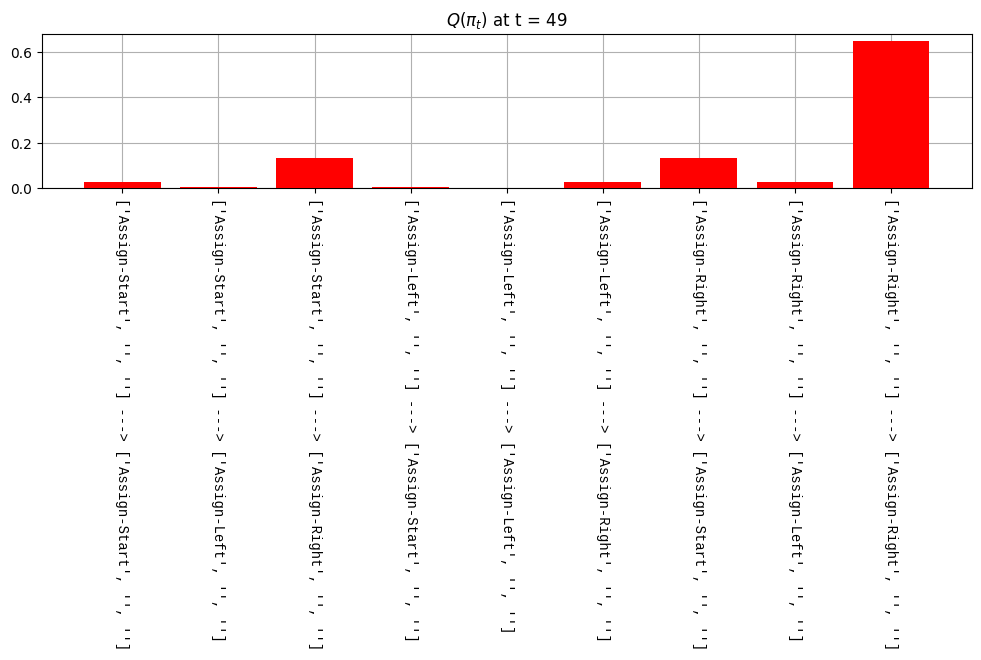

### ACT FUTURE ###
!!!!!!!!!! act_idx=array([2, 0, 0], dtype=int32)
a_facs:
{'aAssign': ['Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right', 'Assign-Right'], 'aNull1': ['Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 'Null1', 

In [197]:
# T = 5 ## number of timesteps
# T = 10 ## number of timesteps
# T = 20 ## number of timesteps
# T = 40 ## number of timesteps
T = 50 ## number of timesteps ############################
# T = 60 ## number of timesteps
assert(len(avails['Left']) >= T)
a_facs = {'aAssign': [], 'aNull1': [], 'aNull2': []}
s_facs = {
    'sAssigned': [], 
    'sAvail': {
        'Left': [],
        'Right': [],
    },
}
sˣ_facs = {
    'sˣAssigned': [], 
    'sˣAvail': {
        'Left': [],
        'Right': [],
    },
}
o_mods = {
    'oAssigned': [], 
    'oRew': {
        'Left': [],
        'Right': [],
    },
    'oAvail': {
        'Left': [],
        'Right': [],
    }
}

## min_F = []
# _QIpiIs = []
QIpiIː = []
# _EFE = []
EFEː = []
## _VFE = []
VFEː = []

run_active_inference_loop(my_agent, my_envir, T=T, rng_key=rng_key)

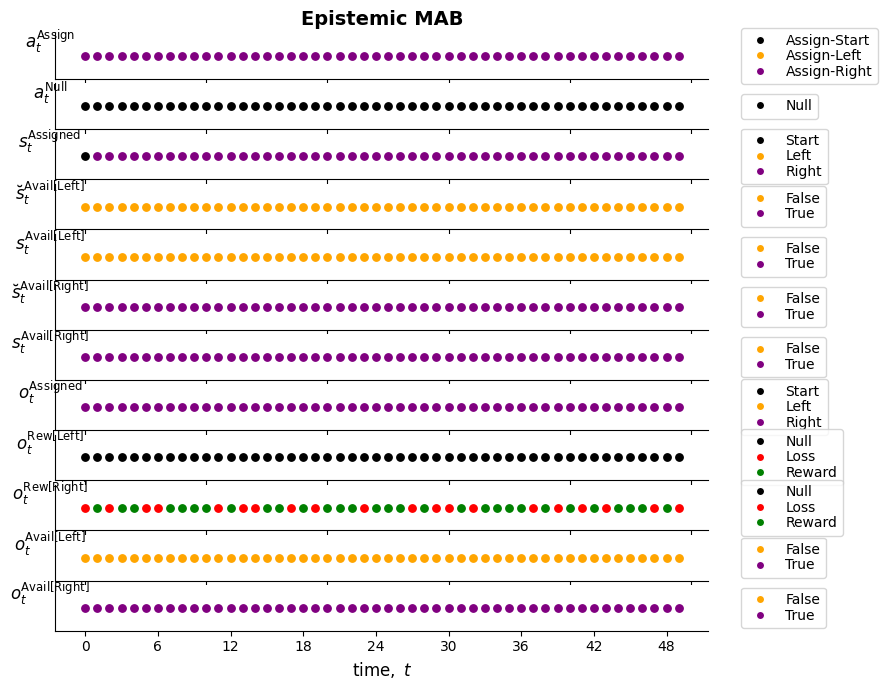

In [198]:
colors = [
{'Assign-Start':'black', 'Assign-Left': 'orange', 'Assign-Right': 'purple'}, ## aAssign
{'Null1':'black'}, ## aNull1

{'Start':'black', 'Left': 'orange', 'Right': 'purple'}, ## sAssigned
{False:'orange', True:'purple'}, ## s̆Avail[Left]
{False:'orange', True:'purple'}, ## sAvail[Left]

{False:'orange', True:'purple'}, ## s̆Avail[Right]
{False:'orange', True:'purple'}, ## sAvail[Right]

{'Start':'black', 'Left': 'orange', 'Right': 'purple'}, ## oAssigned
{'Null':'black', 'Loss':'red', 'Reward': 'green'}, ## oRew[Left]
{'Null':'black', 'Loss':'red', 'Reward': 'green'}, ## oRew[Right]
{False:'orange', True:'purple'}, ## oAvail[Left]
{False:'orange', True:'purple'}, ## oAvail[Right]
]

ylabel_size = 12
msi = 6 ## markersize for Line2D, diameter in points
siz = (msi/2)**2 * np.pi ## size for scatter, area of marker in points squared

# fig = plt.figure(figsize=(9, 6))
fig = plt.figure(figsize=(9, 7))
## gs = GridSpec(6, 1, figure=fig, height_ratios=[1, 3, 1, 3, 3, 1])
# grid_rows = 10
grid_rows = 12
## gs = GridSpec(grid_rows, 1, figure=fig, height_ratios=[1, 1, 1, 1, 1, 1, 1, 1])
gs = GridSpec(grid_rows, 1, figure=fig, height_ratios=[1]*grid_rows)
ax = [fig.add_subplot(gs[i]) for i in range(grid_rows)]

i = 0
ax[i].set_title(f'Epistemic MAB', fontweight='bold',fontsize=14)
y_pos = 0
for t, s in zip(range(T), a_facs['aAssign']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$a^{\mathrm{Assign}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Assign-Start'],markersize=msi,label='Assign-Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Assign-Left'],markersize=msi,label='Assign-Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Assign-Right'],markersize=msi,label='Assign-Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 1
y_pos = 0
for t, s in zip(range(T), a_facs['aNull1']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$a^{\mathrm{Null}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor='black',markersize=msi,label='Null')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 2
y_pos = 0
for t, s in zip(range(T), s_facs['sAssigned']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$s^{\mathrm{Assigned}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Start'],markersize=msi,label='Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left'],markersize=msi,label='Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right'],markersize=msi,label='Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 3
y_pos = 0
for t, s in zip(range(T), sˣ_facs['sˣAvail']['Left']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$s̆^{\mathrm{Avail[Left]}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][False],markersize=msi,label=False),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][True],markersize=msi,label=True)]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 4
y_pos = 0
for t, s in zip(range(T), s_facs['sAvail']['Left']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$s^{\mathrm{Avail[Left]}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][False],markersize=msi,label=False),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][True],markersize=msi,label=True)]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 5
y_pos = 0
for t, s in zip(range(T), sˣ_facs['sˣAvail']['Right']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$s̆^{\mathrm{Avail[Right]}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][False],markersize=msi,label=False),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][True],markersize=msi,label=True)]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 6
y_pos = 0
for t, s in zip(range(T), s_facs['sAvail']['Right']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz)
ax[i].set_ylabel('$s^{\mathrm{Avail[Right]}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
ax[i].set_xticklabels([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][False],markersize=msi,label=False),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][True],markersize=msi,label=True)]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 7
y_pos = 0
for t, s in zip(range(T), o_mods['oAssigned']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Assigned}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Start'],markersize=msi,label='Start'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Left'],markersize=msi,label='Left'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Right'],markersize=msi,label='Right')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 8
y_pos = 0
for t, s in zip(range(T), o_mods['oRew']['Left']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Rew[Left]}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Null'],markersize=msi,label='Null'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Loss'],markersize=msi,label='Loss'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Reward'],markersize=msi,label='Reward')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 9
y_pos = 0
for t, s in zip(range(T), o_mods['oRew']['Right']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Rew[Right]}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Null'],markersize=msi,label='Null'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Loss'],markersize=msi,label='Loss'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i]['Reward'],markersize=msi,label='Reward')]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 10
y_pos = 0
for t, s in zip(range(T), o_mods['oAvail']['Left']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Avail[Left]}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][False],markersize=msi,label=False),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][True],markersize=msi,label=True)]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

i = 11
y_pos = 0
for t, s in zip(range(T), o_mods['oAvail']['Right']):
    ax[i].scatter(t, y_pos, color=colors[i][s], s=siz, label=s)
ax[i].set_ylabel('$o^{\mathrm{Avail[Right]}}_{t}$', rotation=0, fontweight='bold', fontsize=ylabel_size)
ax[i].set_yticks([])
leg_items = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][False],markersize=msi,label=False),
    Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[i][True],markersize=msi,label=True)]
ax[i].legend(handles=leg_items, bbox_to_anchor=(1.05, 0.5), loc='center left', borderaxespad=0, labelspacing=0.1)
ax[i].spines['top'].set_visible(False); ax[i].spines['right'].set_visible(False)

ax[i].xaxis.set_major_locator(MaxNLocator(integer=True))
## ax[i].xaxis.set_major_locator(MaxNLocator(nbins=10, integer=True))
ax[i].set_xlabel('$\mathrm{time,}\ t$', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.subplots_adjust(hspace=0.1) ## Adjust this value as needed
plt.show()

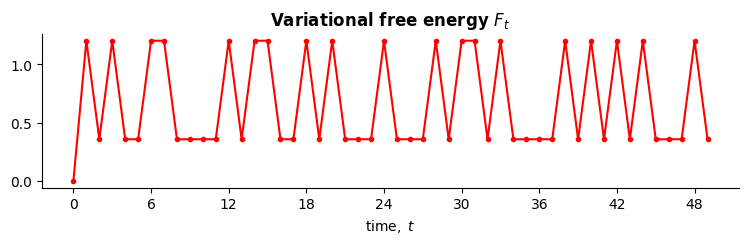

In [199]:
fig, ax = plt.subplots(figsize=(9, 2))
ax.plot(range(len(VFEː)), VFEː, marker='o', color='r', markersize=3)
ax.set_title('Variational free energy $F_t$', fontweight='bold')
ax.set_xlabel('$\\mathrm{time,}\\ t$')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.show()
